In [ ]:
%pip install "xgboost<3.1"

In [2]:
"""
FAERS Adverse Drug Reaction Project
Part 1: Setup + XML Data Loading and Parsing (with year + quarter from filename)
"""

import warnings
warnings.filterwarnings("ignore")

import re
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd
import numpy as np

print("Libraries imported successfully!")

# ============================================================================
# CONFIGURATION
# ============================================================================

class Config:
    """Configuration for file paths and basic settings."""
    # Folder containing FAERS XML files
    DATA_DIR = Path("FAERS DATASET/Dataset/")

    # Make sure folder exists (or adjust path above)
    DATA_DIR.mkdir(exist_ok=True)

config = Config()
print(f"Using data folder: {config.DATA_DIR.resolve()}")

# ============================================================================
# HELPERS
# ============================================================================

def extract_year_quarter(filename):
    """
    Parse FAERS filename formats like:
        1_ADR20Q1.xml
        1_ADR21Q4.xml
        etc.

    Returns
    -------
    year : int or None
    quarter : str or None
    """
    name = Path(filename).stem  # e.g. "1_ADR20Q1"
    parts = name.split("_")
    core = parts[-1]  # e.g. "ADR20Q1"

    # Look for patterns like "20Q1", "21Q4"
    m = re.search(r"(\d{2})Q([1-4])", core)
    if not m:
        return None, None

    yy = int(m.group(1))
    q_num = m.group(2)

    year = 2000 + yy     # assume 20xx
    quarter = f"Q{q_num}"

    return year, quarter


def get_text_safe(element, tag_path, default=None):
    """
    Safely extract text from an XML element.
    Returns `default` if missing or empty.
    """
    elem = element.find(tag_path)
    return elem.text.strip() if elem is not None and elem.text else default

# ============================================================================
# XML PARSING
# ============================================================================

def parse_faers_xml(xml_file):
    """
    Parse a single FAERS XML file and extract:
      - Report-level data
      - Drug-level data
      - Reaction-level data
      - Patient-level data
    Adds year + quarter based on XML filename.

    Parameters
    ----------
    xml_file : str or Path

    Returns
    -------
    dict
        {
          'reports':   [dict, ...],
          'drugs':     [dict, ...],
          'reactions': [dict, ...],
          'patient_info': [dict, ...]
        }
    """
    print(f"Parsing: {xml_file}")

    # Extract year + quarter once per file
    year, quarter = extract_year_quarter(xml_file)
    print(f"  Year: {year}, Quarter: {quarter}")

    try:
        tree = ET.parse(str(xml_file))
        root = tree.getroot()
    except Exception as e:
        print(f"Error parsing XML file {xml_file}: {e}")
        return {
            "reports": [],
            "drugs": [],
            "reactions": [],
            "patient_info": [],
        }

    data = {
        "reports": [],
        "drugs": [],
        "reactions": [],
        "patient_info": [],
    }

    # Find all safety reports
    safety_reports = root.findall(".//safetyreport")
    if len(safety_reports) == 0:
        safety_reports = root.findall("safetyreport")

    print(f"  Found {len(safety_reports)} safety reports")

    for safety_report in safety_reports:
        # --- Report-level fields ---
        report_id = get_text_safe(safety_report, "safetyreportid")
        country = get_text_safe(safety_report, "primarysourcecountry", "Unknown")
        occur_country = get_text_safe(safety_report, "occurcountry", "Unknown")
        report_type = get_text_safe(safety_report, "reporttype")

        serious_text = get_text_safe(safety_report, "serious", "0")
        try:
            serious = int(serious_text)
        except (ValueError, TypeError):
            serious = 0

        trans_date = get_text_safe(safety_report, "transmissiondate")
        recv_date = get_text_safe(safety_report, "receivedate")
        rcpt_date = get_text_safe(safety_report, "receiptdate")

        seriousness_death = get_text_safe(safety_report, "seriousnessdeath", "0")
        seriousness_hosp = get_text_safe(
            safety_report, "seriousnesshospitalization", "0"
        )
        seriousness_disabling = get_text_safe(
            safety_report, "seriousnessdisabling", "0"
        )
        seriousness_lifethreat = get_text_safe(
            safety_report, "seriousnesslifethreatening", "0"
        )
        seriousness_other = get_text_safe(safety_report, "seriousnessother", "0")

        report_summary = {
            "safetyreportid": report_id,
            "year": year,
            "quarter": quarter,
            "primarysourcecountry": country,
            "occurcountry": occur_country,
            "reporttype": report_type,
            "serious": serious,
            "transmissiondate": trans_date,
            "receivedate": recv_date,
            "receiptdate": rcpt_date,
            "seriousnessdeath": seriousness_death,
            "seriousnesshospitalization": seriousness_hosp,
            "seriousnessdisabling": seriousness_disabling,
            "seriousnesslifethreatening": seriousness_lifethreat,
            "seriousnessother": seriousness_other,
        }
        data["reports"].append(report_summary)

        # --- Patient-level fields ---
        patient = safety_report.find("patient")
        if patient is not None:
            age_text = get_text_safe(patient, "patientonsetage")
            try:
                age_val = float(age_text) if age_text else None
            except (ValueError, TypeError):
                age_val = None

            age_unit_val = get_text_safe(patient, "patientonsetageunit")

            weight_text = get_text_safe(patient, "patientweight")
            try:
                weight_val = float(weight_text) if weight_text else None
            except (ValueError, TypeError):
                weight_val = None

            sex_val = get_text_safe(patient, "patientsex")

            patient_info = {
                "safetyreportid": report_id,
                "year": year,
                "quarter": quarter,
                "age": age_val,
                "age_unit": age_unit_val,
                "weight": weight_val,
                "sex": sex_val,
            }
            data["patient_info"].append(patient_info)

            # --- Drugs ---
            for drug in patient.findall("drug"):
                med_product = get_text_safe(drug, "medicinalproduct")
                drug_char_val = get_text_safe(drug, "drugcharacterization")
                auth_num = get_text_safe(drug, "drugauthorizationnumb")
                dosage_form_val = get_text_safe(drug, "drugdosageform")
                dosage_text_val = get_text_safe(drug, "drugdosagetext")
                admin_route_val = get_text_safe(drug, "drugadministrationroute")
                indication_val = get_text_safe(drug, "drugindication")
                start_date_val = get_text_safe(drug, "drugstartdate")
                end_date_val = get_text_safe(drug, "drugenddate")
                action_drug_val = get_text_safe(drug, "actiondrug")

                drug_info = {
                    "safetyreportid": report_id,
                    "year": year,
                    "quarter": quarter,
                    "medicinalproduct": med_product,
                    "drugcharacterization": drug_char_val,
                    "drugauthorizationnumb": auth_num,
                    "drugdosageform": dosage_form_val,
                    "drugdosagetext": dosage_text_val,
                    "drugadministrationroute": admin_route_val,
                    "drugindication": indication_val,
                    "drugstartdate": start_date_val,
                    "drugenddate": end_date_val,
                    "actiondrug": action_drug_val,
                }
                data["drugs"].append(drug_info)

            # --- Reactions ---
            for reaction in patient.findall("reaction"):
                reaction_name = get_text_safe(reaction, "reactionmeddrapt")
                version = get_text_safe(reaction, "reactionmeddraversionpt")
                outcome = get_text_safe(reaction, "reactionoutcome")

                reaction_info = {
                    "safetyreportid": report_id,
                    "year": year,
                    "quarter": quarter,
                    "reactionmeddrapt": reaction_name,
                    "reactionmeddraversionpt": version,
                    "reactionoutcome": outcome,
                }
                data["reactions"].append(reaction_info)

    return data

# ============================================================================
# LOADING MULTIPLE FILES + DATAFRAMES
# ============================================================================

def load_multiple_xml_files(file_list):
    """
    Load and combine multiple FAERS XML files.

    Parameters
    ----------
    file_list : list[Path or str]

    Returns
    -------
    dict
        Combined data across all files.
    """
    combined_data = {
        "reports": [],
        "drugs": [],
        "reactions": [],
        "patient_info": [],
    }

    for i, xml_file in enumerate(file_list, start=1):
        print(f"\nProcessing file {i}/{len(file_list)}: {Path(xml_file).name}")
        file_data = parse_faers_xml(xml_file)

        for key in combined_data.keys():
            combined_data[key].extend(file_data[key])

        print("  ✓ Done")

    print("\n" + "=" * 60)
    print("SUMMARY OF LOADED DATA")
    print("=" * 60)
    print(f"Total reports:       {len(combined_data['reports'])}")
    print(f"Total drugs:         {len(combined_data['drugs'])}")
    print(f"Total reactions:     {len(combined_data['reactions'])}")
    print(f"Total patient info:  {len(combined_data['patient_info'])}")

    return combined_data


def create_dataframes(parsed_data):
    """
    Convert parsed XML data into pandas DataFrames.

    Returns
    -------
    reports_df, drugs_df, reactions_df, patient_df
    """
    reports_df = pd.DataFrame(parsed_data["reports"])
    drugs_df = pd.DataFrame(parsed_data["drugs"])
    reactions_df = pd.DataFrame(parsed_data["reactions"])
    patient_df = pd.DataFrame(parsed_data["patient_info"])

    print("\nDataFrames created:")
    print(f"  Reports:   {len(reports_df)}")
    print(f"  Drugs:     {len(drugs_df)}")
    print(f"  Reactions: {len(reactions_df)}")
    print(f"  Patients:  {len(patient_df)}")

    return reports_df, drugs_df, reactions_df, patient_df

# ============================================================================
# EXAMPLE USAGE
# ============================================================================

if __name__ == "__main__":
    # Load all XML files from config.DATA_DIR
    xml_files = list(config.DATA_DIR.glob("*.xml"))
    print(f"Found {len(xml_files)} XML files in {config.DATA_DIR}")

    if xml_files:
        parsed_data = load_multiple_xml_files(xml_files)
        reports_df, drugs_df, reactions_df, patient_df = create_dataframes(parsed_data)

    else:
        print("No XML files found. Put your FAERS XML files into the data folder and rerun.")


Libraries imported successfully!
Using data folder: /Users/tanishasingh/Documents/MSIM/FALL '25/IS 597 Machine Learning and Cloud/Final project/FAERS DATASET/Dataset
Found 12 XML files in FAERS DATASET/Dataset

Processing file 1/12: 1_ADR22Q2.xml
Parsing: FAERS DATASET/Dataset/1_ADR22Q2.xml
  Year: 2022, Quarter: Q2
  Found 127221 safety reports
  ✓ Done

Processing file 2/12: 1_ADR22Q1.xml
Parsing: FAERS DATASET/Dataset/1_ADR22Q1.xml
  Year: 2022, Quarter: Q1
  Found 147227 safety reports
  ✓ Done

Processing file 3/12: 1_ADR24Q3.xml
Parsing: FAERS DATASET/Dataset/1_ADR24Q3.xml
  Year: 2024, Quarter: Q3
  Found 142944 safety reports
  ✓ Done

Processing file 4/12: 1_ADR22Q4.xml
Parsing: FAERS DATASET/Dataset/1_ADR22Q4.xml
  Year: 2022, Quarter: Q4
  Found 150102 safety reports
  ✓ Done

Processing file 5/12: 1_ADR24Q2.xml
Parsing: FAERS DATASET/Dataset/1_ADR24Q2.xml
  Year: 2024, Quarter: Q2
  Found 125466 safety reports
  ✓ Done

Processing file 6/12: 1_ADR21Q2.xml
Parsing: FAERS DAT


Part 2 Complete: Preprocessing and feature engineering functions ready!

Missing Value Analysis: reports
    Column  Missing_Count  Missing_Percentage Data_Type
reporttype            429                0.03    object


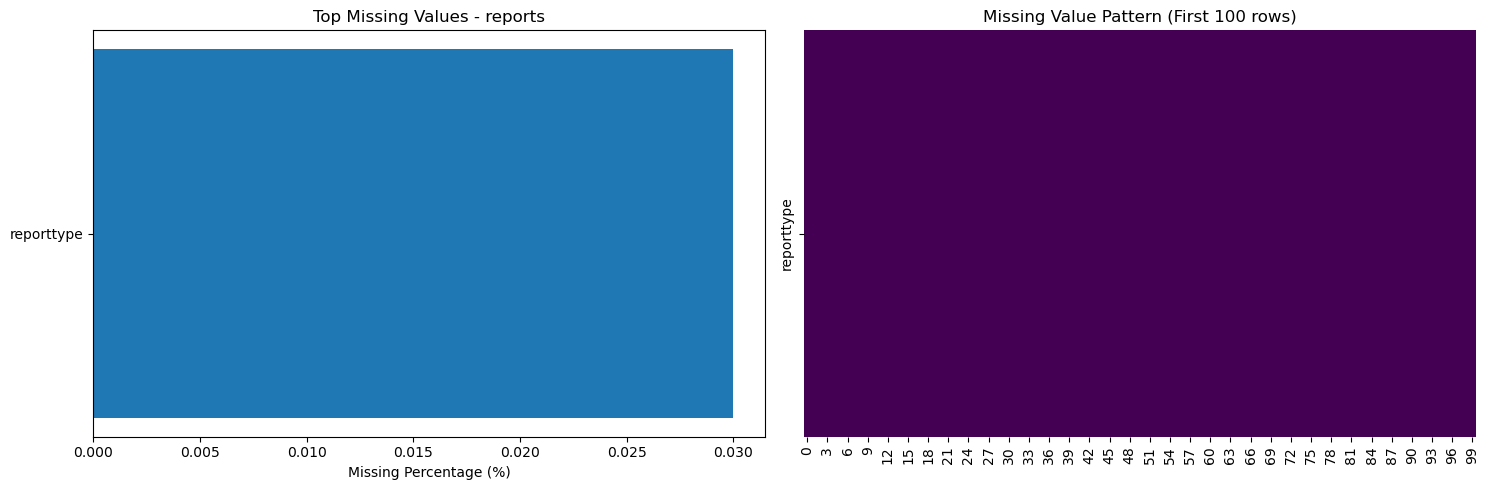


Missing Value Analysis: patient
  Column  Missing_Count  Missing_Percentage Data_Type
  weight        1396724               83.83   float64
     age         715967               42.97   float64
age_unit         715940               42.97    object
     sex         252021               15.13    object


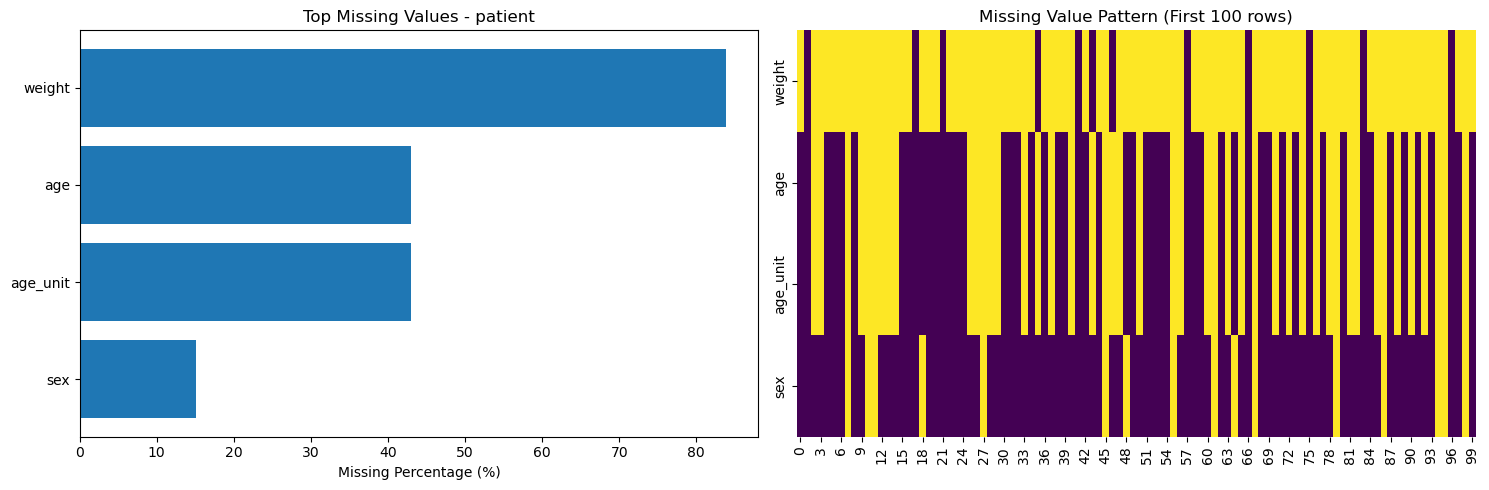


Missing Value Analysis: drugs
                 Column  Missing_Count  Missing_Percentage Data_Type
            drugenddate        6062815               85.04    object
          drugstartdate        4934255               69.21    object
  drugauthorizationnumb        4394151               61.64    object
         drugdosageform        3676065               51.57    object
         drugdosagetext        2998292               42.06    object
         drugindication        2407664               33.77    object
drugadministrationroute        2285704               32.06    object
             actiondrug        2032903               28.52    object
   drugcharacterization              2                0.00    object


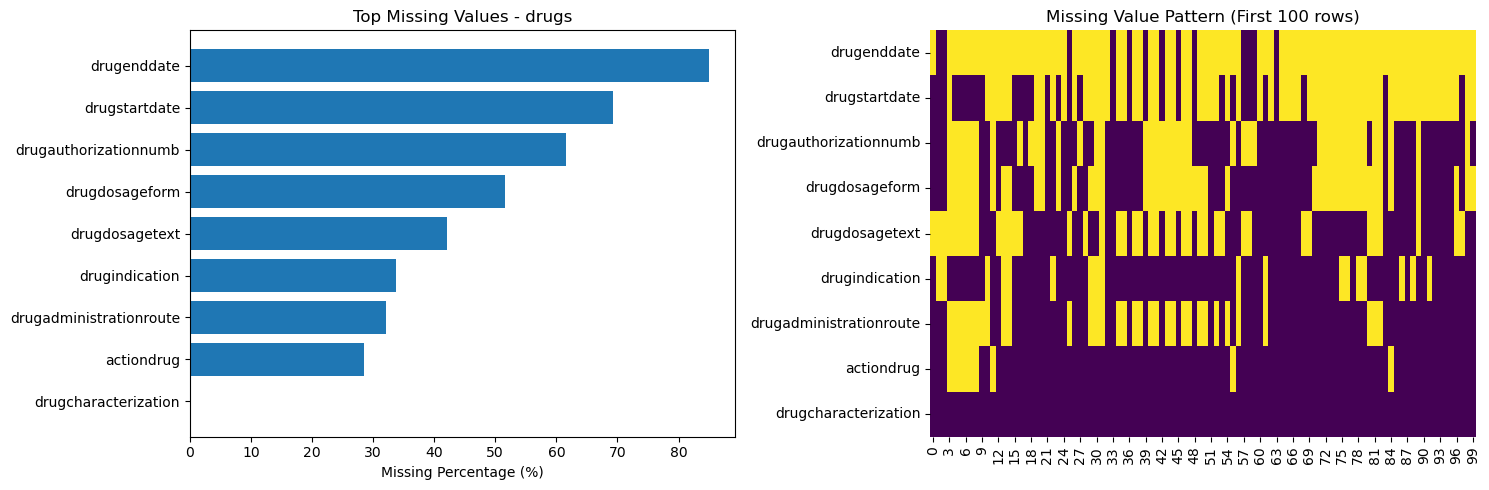


Missing Value Analysis: reactions
          Column  Missing_Count  Missing_Percentage Data_Type
 reactionoutcome         195275                3.61    object
reactionmeddrapt            104                0.00    object


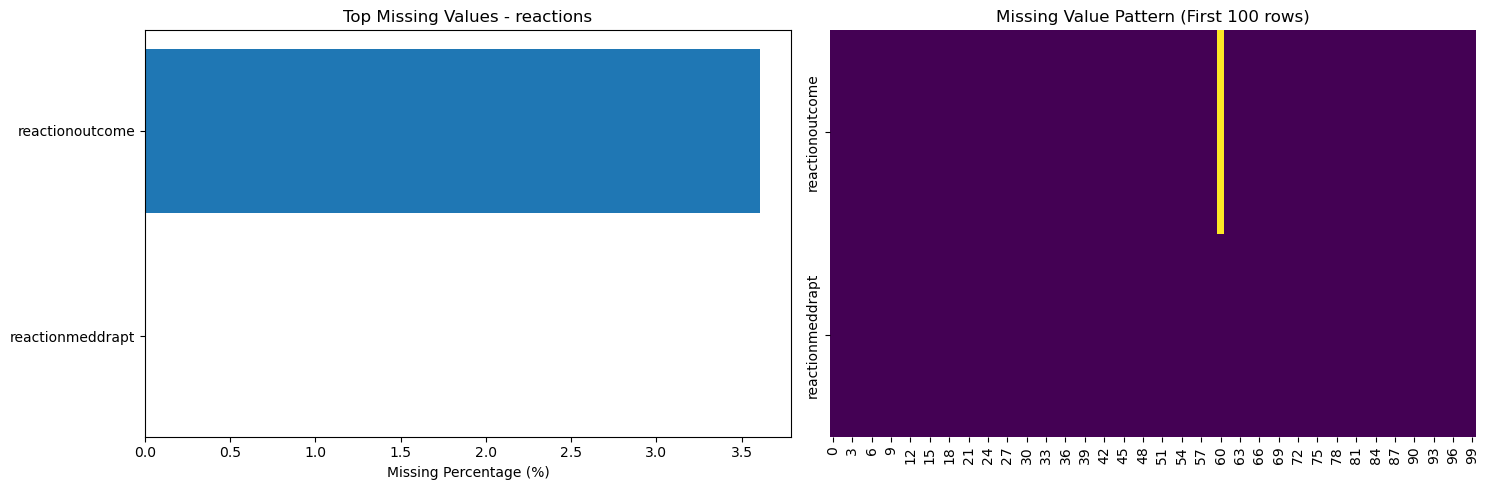


Handling Missing Values...
Missing values handled successfully!

Duplicate Detection
Duplicate reports: 42993
Exact duplicate report rows: 0

After removing duplicates:
  Reports: 1666136 → 1623143
  Drugs: 7128957 → 6719960
  Reactions: 5401818 → 5358004
  Patient: 1666136 → 1623143

Preprocessing text columns...
Text preprocessing complete!

Extracting temporal features...
Temporal features extracted!

Engineering demographic features...
Demographic features engineered!

Merging All Features
Starting with 1623143 reports
After patient merge: 1623143 records

Creating drug-drug interaction features...
Drug interaction features created for 1623143 reports
After drug features merge: 1623143 records

Creating reaction features...
Reaction features created for 1623143 reports
After reaction features merge: 1623143 records

Final dataset shape: (1623143, 47)
Features: 47

Master dataset ready: (1623143, 47)


,safetyreportid,year,quarter,primarysourcecountry,occurcountry,reporttype,serious,transmissiondate,receivedate,receiptdate,...,num_admin_routes,polypharmacy,num_reactions,outcome_1,outcome_2,outcome_3,outcome_4,outcome_5,outcome_6,outcome_Unknown
0,20523663,2022,Q2,US,US,1,1,20220720,20220228,20220428,...,2,1,4,0,0,0,0,0,4,0
1,20732524,2022,Q2,US,US,1,1,20220720,20220420,20220420,...,2,0,4,0,0,0,0,0,4,0
2,20732881,2022,Q2,US,US,1,2,20220720,20220420,20220420,...,2,0,2,0,1,0,0,0,1,0
3,20661703,2022,Q2,ES,ES,1,1,20220720,20220401,20220401,...,1,0,1,1,0,0,0,0,0,0
4,20679307,2022,Q2,CO,CO,2,1,20220720,20220406,20220406,...,1,0,2,0,2,0,0,0,0,0


In [4]:
"""
FAERS Adverse Drug Reaction Prediction - Part 2: Data Preprocessing
Addresses feedback: Comprehensive preprocessing with missing value handling,
duplicate detection, text processing, and feature engineering
"""

import pandas as pd
import numpy as np
from datetime import datetime
import re
from collections import Counter
from pathlib import Path

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

# ============================================================================
# MISSING VALUE ANALYSIS AND HANDLING
# ============================================================================

def analyze_missing_values(df, name="DataFrame"):
    """
    Comprehensive missing value analysis
    Addresses feedback: Missing value strategy
    """
    print(f"\n{'='*60}")
    print(f"Missing Value Analysis: {name}")
    print(f"{'='*60}")
    
    missing_stats = pd.DataFrame({
        'Column': df.columns,
        'Missing_Count': df.isnull().sum(),
        'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2),
        'Data_Type': df.dtypes
    })
    missing_stats = missing_stats[missing_stats['Missing_Count'] > 0].sort_values(
        'Missing_Percentage', ascending=False
    )
    
    if len(missing_stats) > 0:
        print(missing_stats.to_string(index=False))
        
        import matplotlib.pyplot as plt
        import seaborn as sns
        
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        
        # Bar plot of missing percentages
        top_missing = missing_stats.head(15)
        axes[0].barh(top_missing['Column'], top_missing['Missing_Percentage'])
        axes[0].set_xlabel('Missing Percentage (%)')
        axes[0].set_title(f'Top Missing Values - {name}')
        axes[0].invert_yaxis()
        
        # Heatmap of missing values
        missing_mask = df[missing_stats['Column'].head(10)].isnull()
        sns.heatmap(missing_mask.head(100).T, cbar=False, ax=axes[1], cmap='viridis')
        axes[1].set_title('Missing Value Pattern (First 100 rows)')
        
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f'missing_values_{name}.png', dpi=300, bbox_inches='tight')
        plt.show()
    else:
        print("No missing values found!")
    
    return missing_stats


def handle_missing_values(reports_df, drugs_df, reactions_df, patient_df):
    """
    Implement comprehensive missing value handling strategy
    """
    print("\nHandling Missing Values...")
    
    # Reports DataFrame
    reports_clean = reports_df.copy()
    reports_clean['primarysourcecountry'].fillna('Unknown', inplace=True)
    reports_clean['occurcountry'].fillna('Unknown', inplace=True)
    reports_clean['reporttype'].fillna('Unknown', inplace=True)
    reports_clean['serious'].fillna(0, inplace=True)
    
    # Patient DataFrame
    patient_clean = patient_df.copy()
    patient_clean['age'].fillna(patient_clean['age'].median(), inplace=True)
    patient_clean['age_unit'].fillna('Unknown', inplace=True)
    patient_clean['weight'].fillna(patient_clean['weight'].median(), inplace=True)
    patient_clean['sex'].fillna('Unknown', inplace=True)
    
    # Drugs DataFrame
    drugs_clean = drugs_df.copy()
    drugs_clean['medicinalproduct'].fillna('Unknown_Drug', inplace=True)
    drugs_clean['drugcharacterization'].fillna('Unknown', inplace=True)
    drugs_clean['drugdosageform'].fillna('Unknown', inplace=True)
    drugs_clean['drugadministrationroute'].fillna('Unknown', inplace=True)
    drugs_clean['drugindication'].fillna('Unknown', inplace=True)
    
    # Reactions DataFrame
    reactions_clean = reactions_df.copy()
    reactions_clean['reactionmeddrapt'].fillna('Unknown_Reaction', inplace=True)
    reactions_clean['reactionoutcome'].fillna('Unknown', inplace=True)
    
    print("Missing values handled successfully!")
    return reports_clean, drugs_clean, reactions_clean, patient_clean

# ============================================================================
# DUPLICATE DETECTION
# ============================================================================

def detect_and_handle_duplicates(reports_df, drugs_df, reactions_df, patient_df):
    """
    Detect and handle duplicate records
    Addresses feedback: Duplicate detection
    """
    print("\n" + "="*60)
    print("Duplicate Detection")
    print("="*60)
    
    # Check reports
    report_dupes = reports_df.duplicated(subset=['safetyreportid']).sum()
    print(f"Duplicate reports: {report_dupes}")
    
    # Check exact duplicate rows
    exact_dupes = reports_df.duplicated().sum()
    print(f"Exact duplicate report rows: {exact_dupes}")
    
    # Remove duplicates
    reports_clean = reports_df.drop_duplicates(subset=['safetyreportid'], keep='first')
    drugs_clean = drugs_df.drop_duplicates()
    reactions_clean = reactions_df.drop_duplicates()
    patient_clean = patient_df.drop_duplicates(subset=['safetyreportid'], keep='first')
    
    print(f"\nAfter removing duplicates:")
    print(f"  Reports: {len(reports_df)} → {len(reports_clean)}")
    print(f"  Drugs: {len(drugs_df)} → {len(drugs_clean)}")
    print(f"  Reactions: {len(reactions_df)} → {len(reactions_clean)}")
    print(f"  Patient: {len(patient_df)} → {len(patient_clean)}")
    
    return reports_clean, drugs_clean, reactions_clean, patient_clean

# ============================================================================
# TEXT PREPROCESSING
# ============================================================================

def preprocess_text(text):
    """
    Clean and standardize text fields
    Addresses feedback: Text preprocessing
    """
    if pd.isna(text) or text == 'Unknown_Drug' or text == 'Unknown_Reaction':
        return text
    
    text = str(text).upper()
    text = re.sub(r'[^A-Z0-9\s\-]', ' ', text)
    text = ' '.join(text.split())
    return text


def preprocess_text_columns(drugs_df, reactions_df):
    """
    Apply text preprocessing to relevant columns
    """
    print("\nPreprocessing text columns...")
    
    drugs_clean = drugs_df.copy()
    reactions_clean = reactions_df.copy()
    
    drugs_clean['medicinalproduct'] = drugs_clean['medicinalproduct'].apply(preprocess_text)
    drugs_clean['drugindication'] = drugs_clean['drugindication'].apply(preprocess_text)
    
    reactions_clean['reactionmeddrapt'] = reactions_clean['reactionmeddrapt'].apply(preprocess_text)
    
    print("Text preprocessing complete!")
    return drugs_clean, reactions_clean

# ============================================================================
# DATE PARSING AND TEMPORAL FEATURES
# ============================================================================

def parse_faers_date(date_str):
    """
    Parse FAERS date format (YYYYMMDD)
    """
    if pd.isna(date_str):
        return None
    
    try:
        date_str = str(date_str)
        if len(date_str) == 8:
            return datetime.strptime(date_str, '%Y%m%d')
        elif len(date_str) == 6:
            return datetime.strptime(date_str + '01', '%Y%m%d')
        else:
            return None
    except:
        return None


def extract_temporal_features(reports_df):
    """
    Extract temporal features from dates
    Addresses feedback: More than just year/quarter
    """
    print("\nExtracting temporal features...")
    
    reports_temporal = reports_df.copy()
    
    # Parse dates
    for date_col in ['transmissiondate', 'receivedate', 'receiptdate']:
        if date_col in reports_temporal.columns:
            reports_temporal[f'{date_col}_parsed'] = reports_temporal[date_col].apply(parse_faers_date)
    
    # Extract features from receivedate (most commonly available)
    if 'receivedate_parsed' in reports_temporal.columns:
        reports_temporal['receive_year'] = reports_temporal['receivedate_parsed'].dt.year
        reports_temporal['receive_quarter'] = reports_temporal['receivedate_parsed'].dt.quarter
        reports_temporal['receive_month'] = reports_temporal['receivedate_parsed'].dt.month
        reports_temporal['receive_dayofweek'] = reports_temporal['receivedate_parsed'].dt.dayofweek
        reports_temporal['receive_dayofyear'] = reports_temporal['receivedate_parsed'].dt.dayofyear
        
        reference_date = datetime(2020, 1, 1)
        reports_temporal['days_since_2020'] = (
            reports_temporal['receivedate_parsed'] - reference_date
        ).dt.days
    
    print("Temporal features extracted!")
    return reports_temporal

# ============================================================================
# DRUG-DRUG INTERACTION FEATURES
# ============================================================================

def create_drug_interaction_features(drugs_df):
    """
    Create features for drug-drug interactions
    Addresses feedback: Drug-drug interactions modeling
    """
    print("\nCreating drug-drug interaction features...")
    
    drugs_per_report = drugs_df.groupby('safetyreportid').size().reset_index(name='num_drugs')
    
    drug_char_counts = drugs_df.groupby('safetyreportid')['drugcharacterization'].value_counts().unstack(fill_value=0)
    drug_char_counts = drug_char_counts.add_prefix('drugchar_')
    drug_char_counts = drug_char_counts.reset_index()
    
    admin_routes = drugs_df.groupby('safetyreportid')['drugadministrationroute'].nunique().reset_index(
        name='num_admin_routes'
    )
    
    drug_features = drugs_per_report.merge(drug_char_counts, on='safetyreportid', how='left')
    drug_features = drug_features.merge(admin_routes, on='safetyreportid', how='left')
    
    drug_features['polypharmacy'] = (drug_features['num_drugs'] >= 5).astype(int)
    
    print(f"Drug interaction features created for {len(drug_features)} reports")
    return drug_features

# ============================================================================
# REACTION FEATURES
# ============================================================================

def create_reaction_features(reactions_df):
    """
    Create features from reactions
    """
    print("\nCreating reaction features...")
    
    reactions_per_report = reactions_df.groupby('safetyreportid').size().reset_index(name='num_reactions')
    
    outcome_counts = reactions_df.groupby('safetyreportid')['reactionoutcome'].value_counts().unstack(fill_value=0)
    outcome_counts = outcome_counts.add_prefix('outcome_')
    outcome_counts = outcome_counts.reset_index()
    
    reaction_features = reactions_per_report.merge(outcome_counts, on='safetyreportid', how='left')
    
    print(f"Reaction features created for {len(reaction_features)} reports")
    return reaction_features

# ============================================================================
# DEMOGRAPHIC FEATURE ENGINEERING
# ============================================================================

def engineer_demographic_features(patient_df):
    """
    Create demographic features
    Addresses feedback: Demographic engineering
    """
    print("\nEngineering demographic features...")
    
    patient_features = patient_df.copy()
    
    def categorize_age(age):
        if pd.isna(age):
            return 'Unknown'
        elif age < 18:
            return 'Pediatric'
        elif age < 65:
            return 'Adult'
        else:
            return 'Elderly'
    
    patient_features['age_group'] = patient_features['age'].apply(categorize_age)
    
    def categorize_weight(weight):
        if pd.isna(weight):
            return 'Unknown'
        elif weight < 50:
            return 'Underweight'
        elif weight < 90:
            return 'Normal'
        else:
            return 'Overweight'
    
    patient_features['weight_category'] = patient_features['weight'].apply(categorize_weight)
    
    patient_features['age_weight_ratio'] = patient_features['age'] / (patient_features['weight'] + 1)
    
    # Avoid duplicating year/quarter when merging with reports
    patient_features = patient_features.drop(columns=['year', 'quarter'], errors='ignore')
    
    print("Demographic features engineered!")
    return patient_features

# ============================================================================
# CATEGORICAL ENCODING PREPARATION
# ============================================================================

def prepare_categorical_encoding(df, categorical_cols, top_n=50):
    """
    Prepare categorical variables for encoding
    Addresses feedback: Categorical encoding plans
    """
    print(f"\nPreparing categorical encoding for {len(categorical_cols)} columns...")
    
    df_encoded = df.copy()
    encoding_mappings = {}
    
    for col in categorical_cols:
        if col not in df_encoded.columns:
            continue
        
        top_categories = df_encoded[col].value_counts().head(top_n).index.tolist()
        
        df_encoded[col] = df_encoded[col].apply(
            lambda x: x if x in top_categories else 'Other'
        )
        
        encoding_mappings[col] = top_categories
        print(f"  {col}: {len(top_categories)} categories (+ Other)")
    
    return df_encoded, encoding_mappings

# ============================================================================
# MASTER DATA MERGING FUNCTION
# ============================================================================

def merge_all_features(reports_df, drugs_df, reactions_df, patient_df):
    """
    Merge all features into a single dataset
    Addresses feedback: Merging strategy for one-to-many relationships
    Strategy: Aggregate drug and reaction information per report
    """
    print("\n" + "="*60)
    print("Merging All Features")
    print("="*60)
    
    master_df = reports_df.copy()
    print(f"Starting with {len(master_df)} reports")
    
    master_df = master_df.merge(patient_df, on='safetyreportid', how='left')
    print(f"After patient merge: {len(master_df)} records")
    
    drug_features = create_drug_interaction_features(drugs_df)
    master_df = master_df.merge(drug_features, on='safetyreportid', how='left')
    print(f"After drug features merge: {len(master_df)} records")
    
    reaction_features = create_reaction_features(reactions_df)
    master_df = master_df.merge(reaction_features, on='safetyreportid', how='left')
    print(f"After reaction features merge: {len(master_df)} records")
    
    # Only fill NaNs in numeric columns
    numeric_cols = master_df.select_dtypes(include=[np.number]).columns
    master_df[numeric_cols] = master_df[numeric_cols].fillna(0)
    
    print(f"\nFinal dataset shape: {master_df.shape}")
    print(f"Features: {master_df.shape[1]}")
    
    return master_df

# ============================================================================
# PIPELINE EXECUTION (using reports_df, drugs_df, reactions_df, patient_df from Part 1)
# ============================================================================

print("\nPart 2 Complete: Preprocessing and feature engineering functions ready!")

# 1. Missing value analysis (optional but good for report)
analyze_missing_values(reports_df, name="reports")
analyze_missing_values(patient_df, name="patient")
analyze_missing_values(drugs_df, name="drugs")
analyze_missing_values(reactions_df, name="reactions")

# 2. Handle missing values
reports_clean, drugs_clean, reactions_clean, patient_clean = handle_missing_values(
    reports_df, drugs_df, reactions_df, patient_df
)

# 3. Remove duplicates
reports_clean, drugs_clean, reactions_clean, patient_clean = detect_and_handle_duplicates(
    reports_clean, drugs_clean, reactions_clean, patient_clean
)

# 4. Text preprocessing
drugs_clean, reactions_clean = preprocess_text_columns(drugs_clean, reactions_clean)

# 5. Temporal features
reports_temporal = extract_temporal_features(reports_clean)

# 6. Demographic features
patient_features = engineer_demographic_features(patient_clean)

# 7. Merge everything into one master table
master_df = merge_all_features(
    reports_temporal, 
    drugs_clean, 
    reactions_clean, 
    patient_features
)

print("\nMaster dataset ready:", master_df.shape)
master_df.head()



        COMPREHENSIVE EXPLORATORY DATA ANALYSIS

TARGET VARIABLE ANALYSIS

Class Distribution:
  Non-Serious (0): 660,079 (40.67%)
  Serious (1): 963,064 (59.33%)


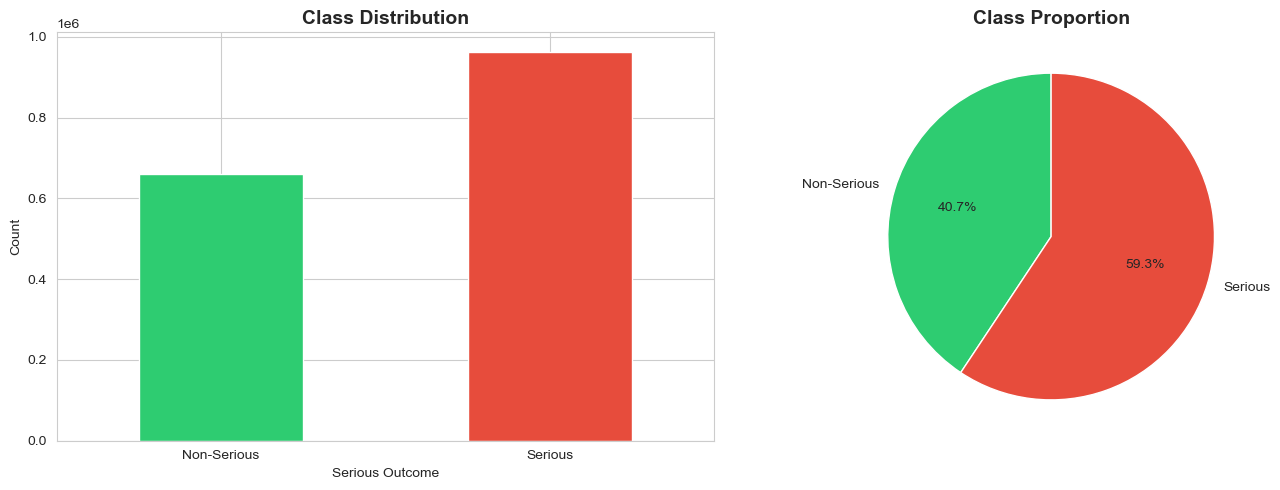


TEMPORAL TRENDS ANALYSIS (YEAR + QUARTER)


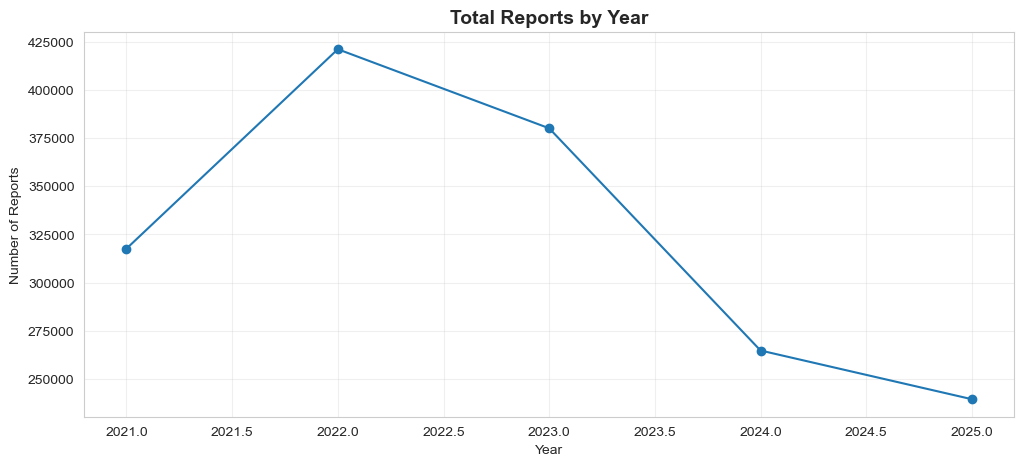

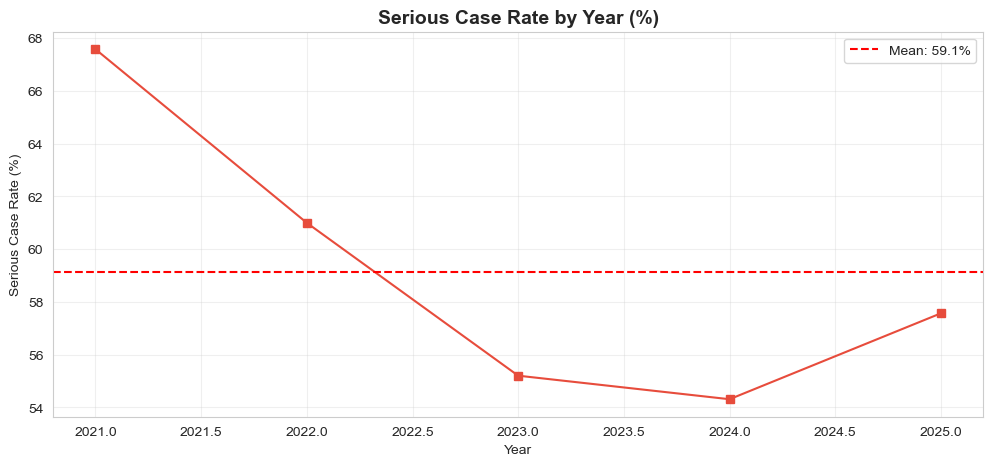

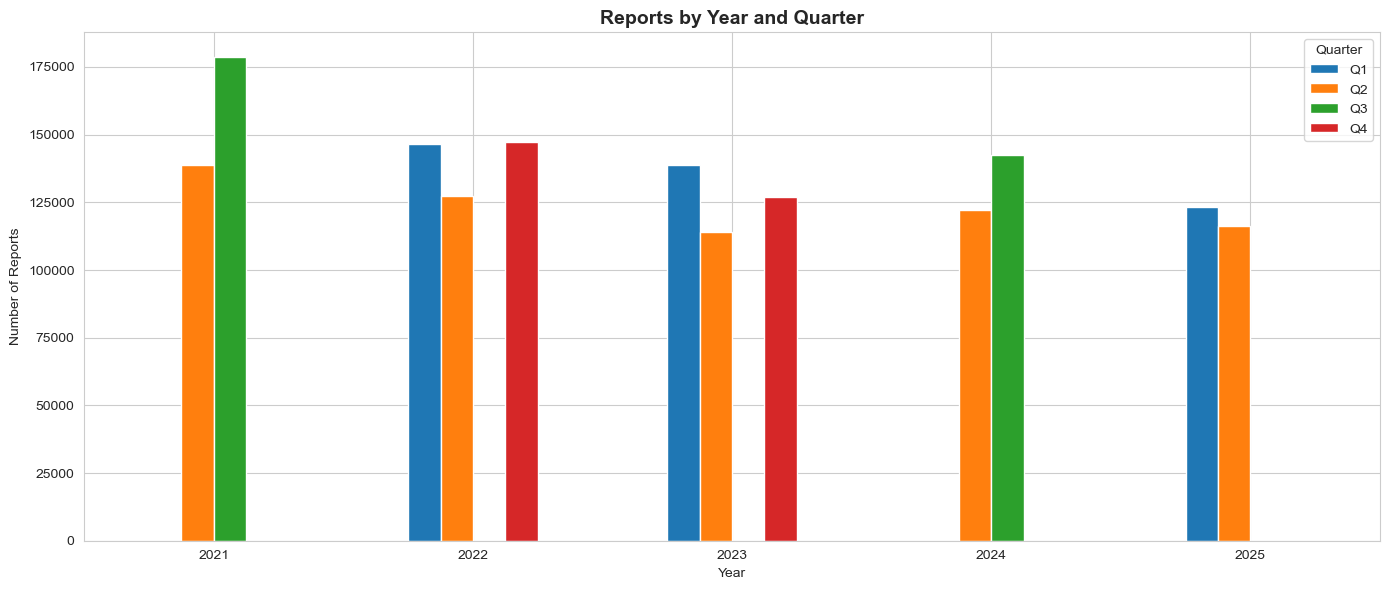


GEOGRAPHIC PATTERNS ANALYSIS


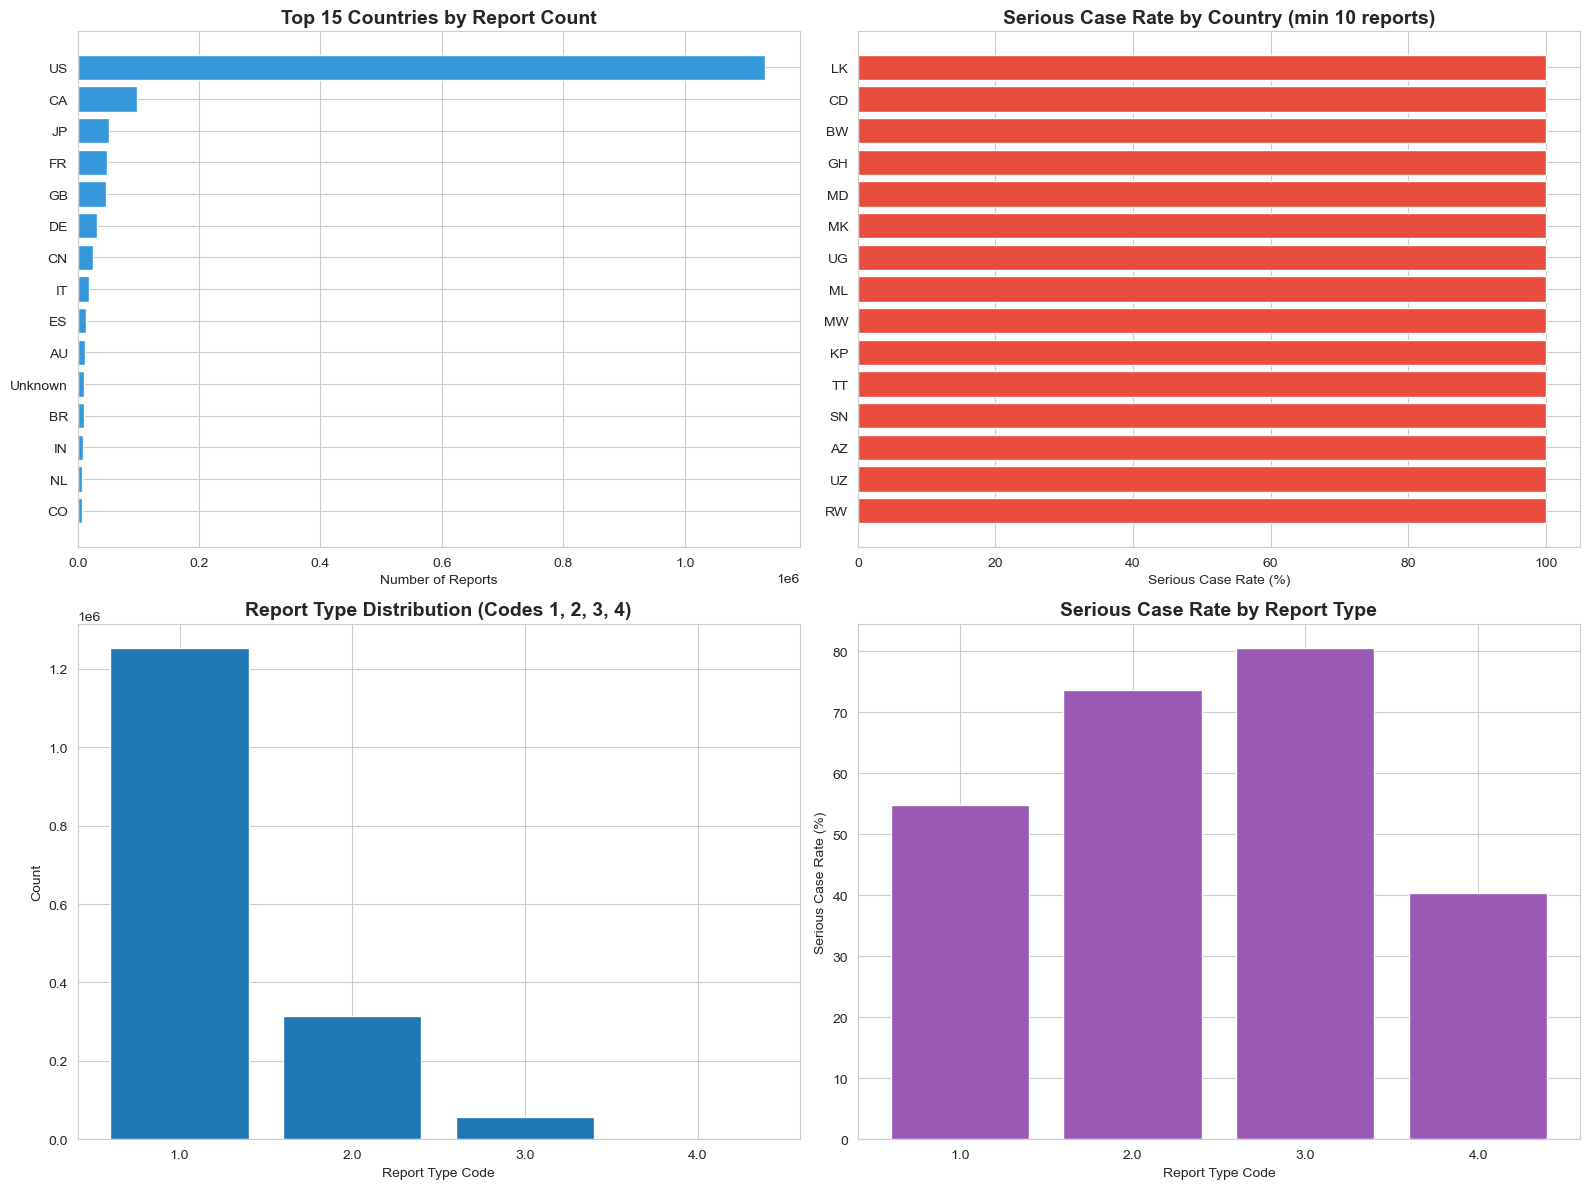


Total unique countries: 200

CORRELATION ANALYSIS


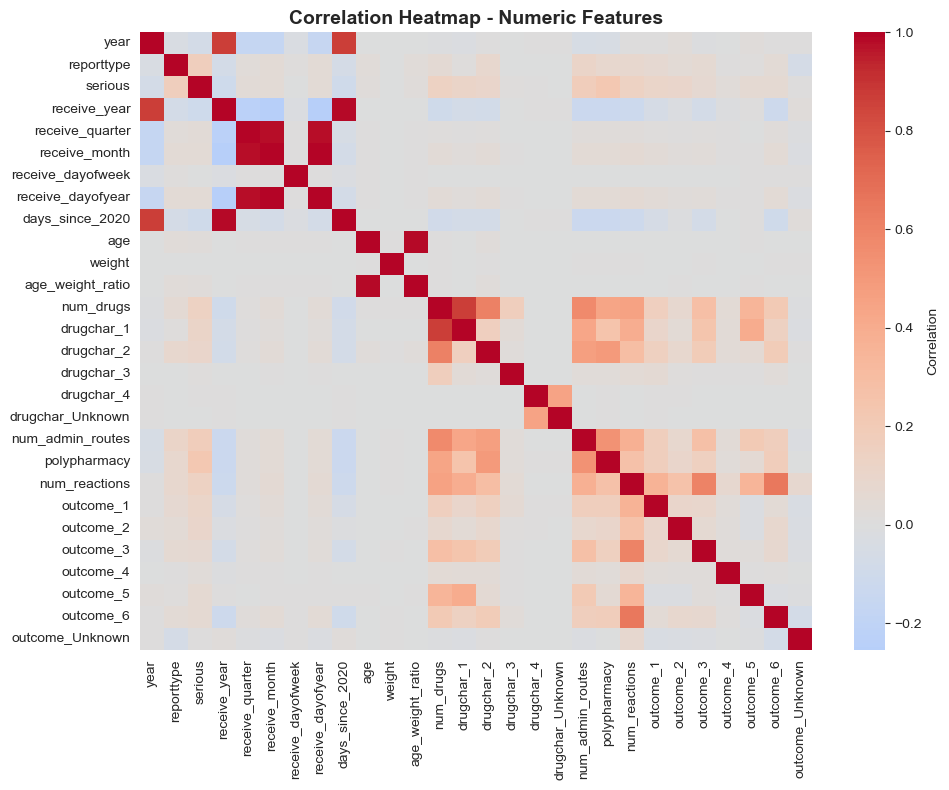


Top 10 positive correlations with Serious:
polypharmacy        0.221547
num_admin_routes    0.178476
reporttype          0.166950
num_reactions       0.141915
num_drugs           0.138233
drugchar_1          0.111841
outcome_1           0.104952
drugchar_2          0.100036
outcome_2           0.099406
outcome_3           0.067452
Name: serious, dtype: float64

Top 10 negative correlations with Serious:
age                  0.023074
drugchar_3           0.014222
outcome_Unknown      0.009007
drugchar_4           0.001744
drugchar_Unknown     0.000650
receive_dayofweek   -0.000998
weight              -0.004144
year                -0.076777
days_since_2020     -0.097690
receive_year        -0.102869
Name: serious, dtype: float64

REACTION TYPE DISTRIBUTIONS


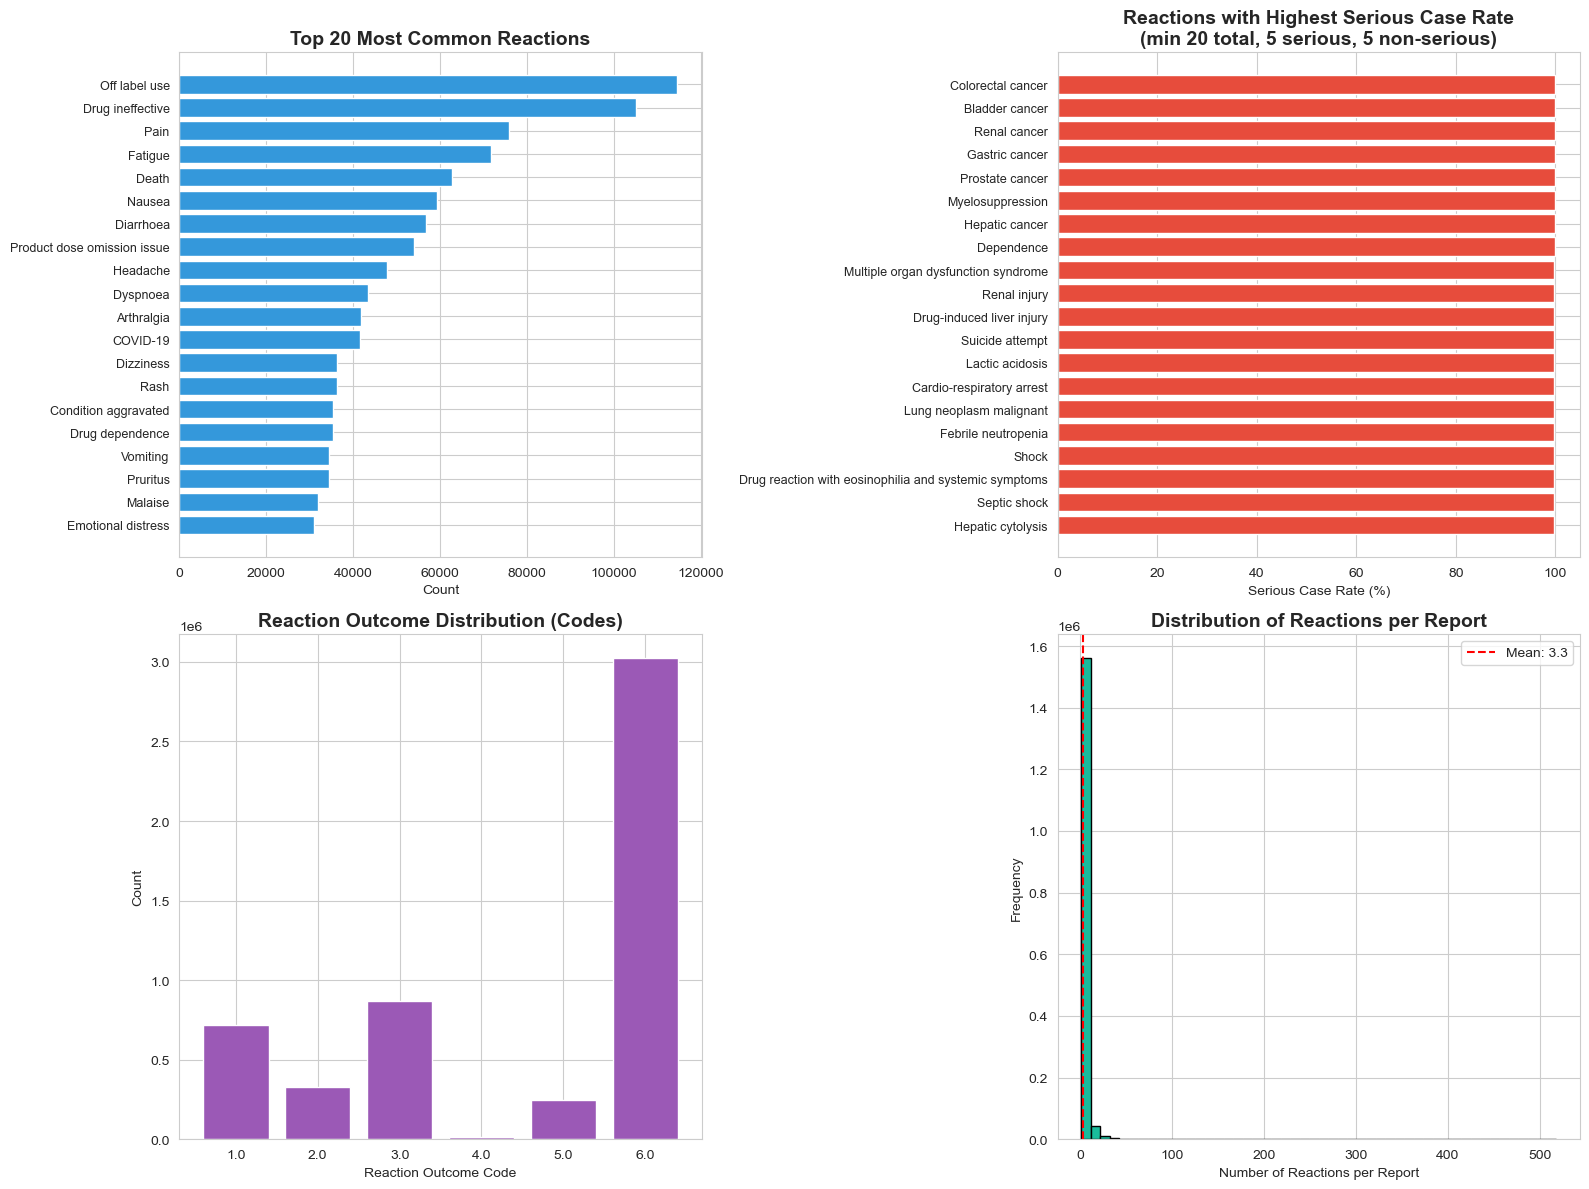


Total unique reactions: 16,937
Average reactions per report: 3.33
Median reactions per report: 2

STATISTICAL HYPOTHESIS TESTING

     Variable  Serious_Mean  NonSerious_Mean       P_Value Significant_0.05
          age    156.514106        92.538298  0.000000e+00              Yes
       weight     72.133256        72.688136 1.248598e-261              Yes
    num_drugs      5.347662         2.378229  0.000000e+00              Yes
num_reactions      3.944700         2.361846  0.000000e+00              Yes

EDA COMPLETE - All plots displayed above.

Part 3 Complete: Comprehensive EDA functions ready!


In [6]:
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# ===============================================================
# CLEANING BEFORE EDA (CRITICAL)
# ===============================================================

def prepare_eda_inputs(master_df, reactions_df, reports_df):
    """
    Ensure serious is binary 0/1 and key fields are numeric
    before any EDA. This fixes:
      - class distribution (0 vs 1)
      - serious rate > 100%
      - reaction serious rate > 100%
      - empty statistical tests
    """
    master_df = master_df.copy()
    reactions_df = reactions_df.copy()
    reports_df = reports_df.copy()

    def binarize_serious(series):
        s = pd.to_numeric(series, errors='coerce')
        # FAERS serious may have codes >1; treat 1 as serious, everything else as non-serious (0)
        return np.where(s == 1, 1, 0).astype(int)

    # Fix serious in both master and reports
    if 'serious' in master_df.columns:
        master_df['serious'] = binarize_serious(master_df['serious'])
    if 'serious' in reports_df.columns:
        reports_df['serious'] = binarize_serious(reports_df['serious'])

    # Numeric conversions in master_df
    for col in ['age', 'weight', 'num_drugs', 'num_reactions']:
        if col in master_df.columns:
            master_df[col] = pd.to_numeric(master_df[col], errors='coerce')

    if 'reporttype' in master_df.columns:
        master_df['reporttype'] = pd.to_numeric(master_df['reporttype'], errors='coerce')

    # reactionoutcome as numeric codes if needed
    if 'reactionoutcome' in reactions_df.columns:
        reactions_df['reactionoutcome'] = pd.to_numeric(
            reactions_df['reactionoutcome'], errors='coerce'
        )

    return master_df, reactions_df, reports_df

# ============================================================================
# TARGET VARIABLE ANALYSIS
# ============================================================================

def analyze_target_variable(df, target_col='serious'):
    print("\n" + "="*60)
    print("TARGET VARIABLE ANALYSIS")
    print("="*60)
    
    value_counts = df[target_col].value_counts().sort_index()
    percentages = df[target_col].value_counts(normalize=True).sort_index() * 100
    
    print(f"\nClass Distribution:")
    for cls in [0, 1]:
        print(f"  {('Non-Serious' if cls == 0 else 'Serious')} ({cls}): "
              f"{value_counts.get(cls, 0):,} ({percentages.get(cls, 0):.2f}%)")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar plot
    value_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
    axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Serious Outcome')
    axes[0].set_ylabel('Count')
    axes[0].set_xticklabels(['Non-Serious', 'Serious'], rotation=0)
    
    # Pie chart
    axes[1].pie(
        value_counts,
        labels=['Non-Serious', 'Serious'],
        autopct='%1.1f%%',
        colors=['#2ecc71', '#e74c3c'],
        startangle=90
    )
    axes[1].set_title('Class Proportion', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    return value_counts

# ============================================================================
# TEMPORAL TRENDS (YEAR + QUARTER)
# ============================================================================

def analyze_temporal_trends(df):
    print("\n" + "="*60)
    print("TEMPORAL TRENDS ANALYSIS (YEAR + QUARTER)")
    print("="*60)
    
    if 'year' not in df.columns or 'quarter' not in df.columns:
        print("No year/quarter columns available.")
        return
    
    # Reports per year
    yearly_counts = df.groupby('year').size()
    plt.figure(figsize=(12, 5))
    plt.plot(yearly_counts.index, yearly_counts.values, marker='o')
    plt.title('Total Reports by Year', fontsize=14, fontweight='bold')
    plt.xlabel('Year')
    plt.ylabel('Number of Reports')
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # Serious rate per year
    yearly_serious_rate = df.groupby('year')['serious'].mean() * 100
    plt.figure(figsize=(12, 5))
    plt.plot(yearly_serious_rate.index, yearly_serious_rate.values, marker='s', color='#e74c3c')
    plt.title('Serious Case Rate by Year (%)', fontsize=14, fontweight='bold')
    plt.xlabel('Year')
    plt.ylabel('Serious Case Rate (%)')
    plt.grid(True, alpha=0.3)
    plt.axhline(
        y=yearly_serious_rate.mean(),
        color='red',
        linestyle='--',
        label=f'Mean: {yearly_serious_rate.mean():.1f}%'
    )
    plt.legend()
    plt.show()
    
    # Year x Quarter counts
    yq_counts = df.groupby(['year', 'quarter']).size().unstack(fill_value=0)
    yq_counts.plot(kind='bar', figsize=(14, 6))
    plt.title('Reports by Year and Quarter', fontsize=14, fontweight='bold')
    plt.xlabel('Year')
    plt.ylabel('Number of Reports')
    plt.xticks(rotation=0)
    plt.legend(title='Quarter')
    plt.tight_layout()
    plt.show()

# ============================================================================
# GEOGRAPHIC PATTERNS ANALYSIS
# ============================================================================

def analyze_geographic_patterns(df):
    print("\n" + "="*60)
    print("GEOGRAPHIC PATTERNS ANALYSIS")
    print("="*60)
    
    if 'primarysourcecountry' not in df.columns:
        print("No primarysourcecountry column in dataframe.")
        return
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Top countries by report count
    top_countries = df['primarysourcecountry'].value_counts().head(15)
    axes[0, 0].barh(range(len(top_countries)), top_countries.values, color='#3498db')
    axes[0, 0].set_yticks(range(len(top_countries)))
    axes[0, 0].set_yticklabels(top_countries.index)
    axes[0, 0].set_xlabel('Number of Reports')
    axes[0, 0].set_title('Top 15 Countries by Report Count', fontsize=14, fontweight='bold')
    axes[0, 0].invert_yaxis()
    
    # 2. Serious case rate by country (correct, <=100%)
    country_stats = df.groupby('primarysourcecountry')['serious'].agg(['mean', 'count'])
    country_stats = country_stats[country_stats['count'] >= 10]  # at least 10 reports
    country_stats['serious_rate'] = country_stats['mean'] * 100
    top_serious_countries = country_stats.sort_values('serious_rate', ascending=False).head(15)
    
    axes[0, 1].barh(
        range(len(top_serious_countries)),
        top_serious_countries['serious_rate'],
        color='#e74c3c'
    )
    axes[0, 1].set_yticks(range(len(top_serious_countries)))
    axes[0, 1].set_yticklabels(top_serious_countries.index)
    axes[0, 1].set_xlabel('Serious Case Rate (%)')
    axes[0, 1].set_title('Serious Case Rate by Country (min 10 reports)',
                         fontsize=14, fontweight='bold')
    axes[0, 1].invert_yaxis()
    
    # 3. Report type distribution (codes 1,2,3,4)
    if 'reporttype' in df.columns:
        rt_counts = df['reporttype'].value_counts().sort_index()
        axes[1, 0].bar(rt_counts.index.astype(str), rt_counts.values)
        axes[1, 0].set_xlabel('Report Type Code')
        axes[1, 0].set_ylabel('Count')
        axes[1, 0].set_title('Report Type Distribution (Codes 1, 2, 3, 4)',
                             fontsize=14, fontweight='bold')
    
        # 4. Serious case rate by report type (<=100%)
        rt_rate = df.groupby('reporttype')['serious'].mean() * 100
        axes[1, 1].bar(rt_rate.index.astype(str), rt_rate.values, color='#9b59b6')
        axes[1, 1].set_xlabel('Report Type Code')
        axes[1, 1].set_ylabel('Serious Case Rate (%)')
        axes[1, 1].set_title('Serious Case Rate by Report Type',
                             fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nTotal unique countries: {df['primarysourcecountry'].nunique()}")

# ============================================================================
# CORRELATION ANALYSIS
# ============================================================================

def analyze_correlations(df):
    print("\n" + "="*60)
    print("CORRELATION ANALYSIS")
    print("="*60)
    
    numeric_df = df.select_dtypes(include=[np.number]).copy()
    
    if 'serious' not in numeric_df.columns:
        print("Numeric 'serious' column not found; skipping correlation.")
        return None, None
    
    corr_matrix = numeric_df.corr()
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=False,
        cmap='coolwarm',
        center=0,
        cbar_kws={'label': 'Correlation'}
    )
    plt.title('Correlation Heatmap - Numeric Features', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    target_corr = corr_matrix['serious'].drop('serious').sort_values(ascending=False)
    
    print("\nTop 10 positive correlations with Serious:")
    print(target_corr.head(10))
    print("\nTop 10 negative correlations with Serious:")
    print(target_corr.tail(10))
    
    return corr_matrix, target_corr

# ============================================================================
# REACTION TYPE DISTRIBUTIONS
# ============================================================================

def analyze_reaction_distributions(reactions_df, reports_df):
    print("\n" + "="*60)
    print("REACTION TYPE DISTRIBUTIONS")
    print("="*60)
    
    # Merge serious (already binarized in prepare_eda_inputs)
    merged = reactions_df.merge(
        reports_df[['safetyreportid', 'serious']],
        on='safetyreportid',
        how='left'
    )
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Top reactions by frequency
    top_reactions = reactions_df['reactionmeddrapt'].value_counts().head(20)
    axes[0, 0].barh(range(len(top_reactions)), top_reactions.values, color='#3498db')
    axes[0, 0].set_yticks(range(len(top_reactions)))
    axes[0, 0].set_yticklabels(top_reactions.index, fontsize=9)
    axes[0, 0].set_xlabel('Count')
    axes[0, 0].set_title('Top 20 Most Common Reactions', fontsize=14, fontweight='bold')
    axes[0, 0].invert_yaxis()
    
    # 2. Reactions with highest serious case rate (but must have BOTH serious and non-serious)
    reaction_stats = merged.groupby('reactionmeddrapt').agg(
        serious_count=('serious', 'sum'),
        total_count=('serious', 'count')
    )
    # require at least 20 total AND at least 5 serious AND 5 non-serious
    reaction_stats['nonserious_count'] = reaction_stats['total_count'] - reaction_stats['serious_count']
    reaction_stats = reaction_stats[
        (reaction_stats['total_count'] >= 20) &
        (reaction_stats['serious_count'] >= 5) &
        (reaction_stats['nonserious_count'] >= 5)
    ]
    reaction_stats['serious_rate_pct'] = (reaction_stats['serious_count'] / reaction_stats['total_count']) * 100
    
    top_serious_reactions = reaction_stats.sort_values('serious_rate_pct', ascending=False).head(20)
    
    axes[0, 1].barh(
        range(len(top_serious_reactions)),
        top_serious_reactions['serious_rate_pct'],
        color='#e74c3c'
    )
    axes[0, 1].set_yticks(range(len(top_serious_reactions)))
    axes[0, 1].set_yticklabels(top_serious_reactions.index, fontsize=9)
    axes[0, 1].set_xlabel('Serious Case Rate (%)')
    axes[0, 1].set_title('Reactions with Highest Serious Case Rate\n(min 20 total, 5 serious, 5 non-serious)',
                         fontsize=14, fontweight='bold')
    axes[0, 1].invert_yaxis()
    
    # 3. Reaction outcome distribution (codes)
    if 'reactionoutcome' in reactions_df.columns:
        outcome_dist = reactions_df['reactionoutcome'].value_counts().sort_index()
        axes[1, 0].bar(outcome_dist.index.astype(str), outcome_dist.values, color='#9b59b6')
        axes[1, 0].set_xlabel('Reaction Outcome Code')
        axes[1, 0].set_ylabel('Count')
        axes[1, 0].set_title('Reaction Outcome Distribution (Codes)', fontsize=14, fontweight='bold')
    
    # 4. Number of reactions per report
    reactions_per_report = reactions_df.groupby('safetyreportid').size()
    axes[1, 1].hist(reactions_per_report, bins=50, color='#1abc9c', edgecolor='black')
    axes[1, 1].set_xlabel('Number of Reactions per Report')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Distribution of Reactions per Report', fontsize=14, fontweight='bold')
    axes[1, 1].axvline(
        reactions_per_report.mean(),
        color='red',
        linestyle='--',
        label=f'Mean: {reactions_per_report.mean():.1f}'
    )
    axes[1, 1].legend()
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nTotal unique reactions: {reactions_df['reactionmeddrapt'].nunique():,}")
    print(f"Average reactions per report: {reactions_per_report.mean():.2f}")
    print(f"Median reactions per report: {reactions_per_report.median():.0f}")

# ============================================================================
# STATISTICAL HYPOTHESIS TESTING
# ============================================================================

def perform_statistical_tests(df):
    print("\n" + "="*60)
    print("STATISTICAL HYPOTHESIS TESTING")
    print("="*60)
    
    serious = df[df['serious'] == 1]
    non_serious = df[df['serious'] == 0]
    
    if len(serious) == 0 or len(non_serious) == 0:
        print("No data for one of the groups (serious/non-serious) after cleaning.")
        return pd.DataFrame()
    
    results = []
    
    numeric_cols = ['age', 'weight', 'num_drugs', 'num_reactions']
    
    for col in numeric_cols:
        if col in df.columns:
            s_data = serious[col].dropna()
            ns_data = non_serious[col].dropna()
            
            if len(s_data) > 0 and len(ns_data) > 0:
                stat, p_value = mannwhitneyu(s_data, ns_data, alternative='two-sided')
                results.append({
                    'Variable': col,
                    'Serious_Mean': s_data.mean(),
                    'NonSerious_Mean': ns_data.mean(),
                    'P_Value': p_value,
                    'Significant_0.05': 'Yes' if p_value < 0.05 else 'No'
                })
    
    results_df = pd.DataFrame(results)
    if not results_df.empty:
        print("\n" + results_df.to_string(index=False))
    else:
        print("No numeric variables had valid data in both groups.")
    
    return results_df

# ============================================================================
# COMPREHENSIVE EDA RUNNER
# ============================================================================

def run_comprehensive_eda(reports_df, drugs_df, reactions_df, patient_df, master_df):
    """
    Run all EDA analyses using cleaned inputs.
    """
    # Clean inputs for EDA (fix serious, types, etc.)
    master_clean, reactions_clean, reports_clean = prepare_eda_inputs(
        master_df, reactions_df, reports_df
    )
    
    print("\n" + "="*80)
    print("        COMPREHENSIVE EXPLORATORY DATA ANALYSIS")
    print("="*80)
    
    analyze_target_variable(master_clean)
    analyze_temporal_trends(master_clean)
    analyze_geographic_patterns(master_clean)
    corr_matrix, target_corr = analyze_correlations(master_clean)
    analyze_reaction_distributions(reactions_clean, reports_clean)
    test_results = perform_statistical_tests(master_clean)
    
    print("\n" + "="*80)
    print("EDA COMPLETE - All plots displayed above.")
    print("="*80)
    
    return {
        'correlation_matrix': corr_matrix,
        'target_correlations': target_corr,
        'statistical_tests': test_results
    }

# ============================================================================
# RUN EDA (ASSUMES reports_df, drugs_df, reactions_df, patient_df, master_df FROM PART 1 & 2)
# ============================================================================

eda_results = run_comprehensive_eda(
    reports_df=reports_df,
    drugs_df=drugs_df,
    reactions_df=reactions_df,
    patient_df=patient_df,
    master_df=master_df
)

print("\nPart 3 Complete: Comprehensive EDA functions ready!")



Part 4 functions ready (SMOTE included with safe fallback).

FEATURE PREPARATION AND ENCODING
Original serious unique values (for modeling): [1 2]
Cleaned y unique values (for modeling): [0 1]

Feature Summary:
  Total features: 30
  Numeric features: 14
  Categorical features: 11
  Reducing cardinality of primarysourcecountry: 200 → 50
  Reducing cardinality of occurcountry: 197 → 50
  Reducing cardinality of receivedate: 4144 → 50
  Reducing cardinality of receiptdate: 445 → 50

Train size: 1298514, Test size: 324629

BASELINE MODEL (Majority Class)

Majority Class: 0
Baseline Accuracy: 0.5933

Classification Report:
              precision    recall  f1-score   support

           0       0.59      1.00      0.74    192613
           1       0.00      0.00      0.00    132016

    accuracy                           0.59    324629
   macro avg       0.30      0.50      0.37    324629
weighted avg       0.35      0.59      0.44    324629


Creating preprocessing pipeline...
Preproces

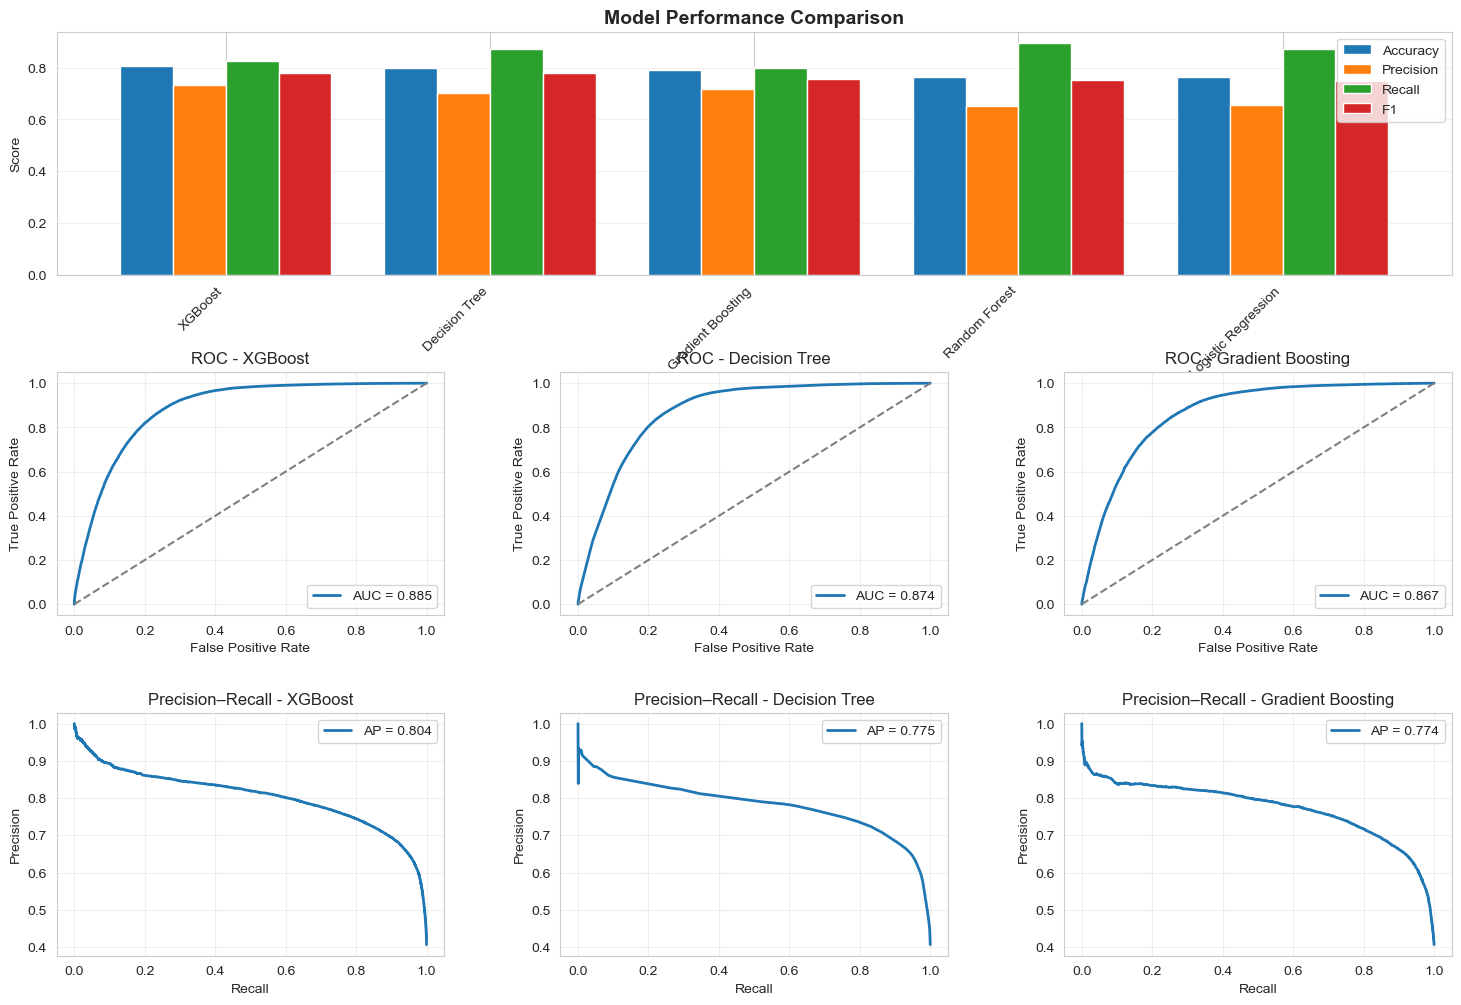

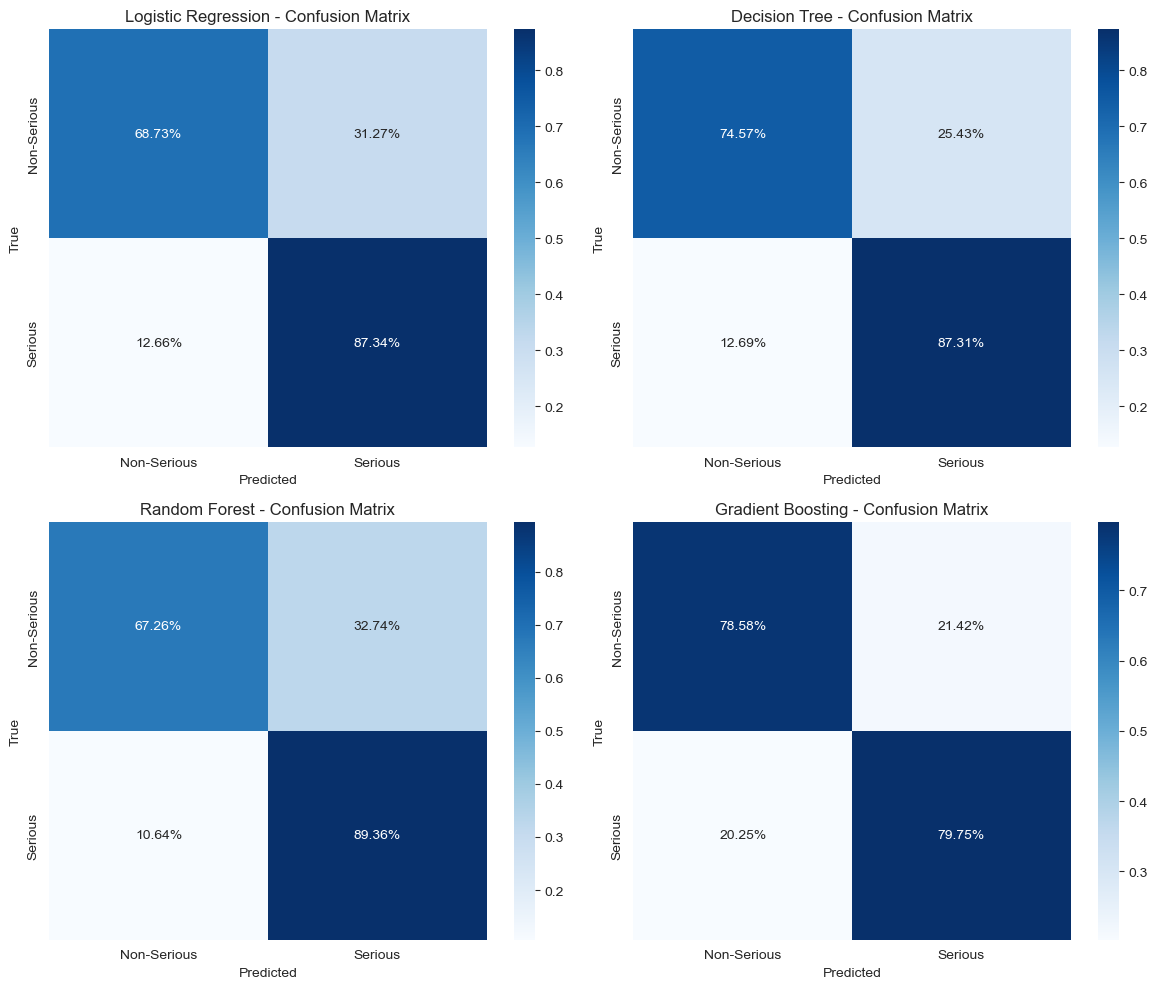

In [33]:
# ============================
# PART 4 – MODELING PIPELINE
# ============================

from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    recall_score,
    accuracy_score,
    precision_score,
    average_precision_score,
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


# Plot style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42

# ============================================================================
# DATA PREPARATION AND FEATURE ENCODING
# ============================================================================

def prepare_features_and_target(master_df, top_n_categories=50):
    """
    Prepare features and target variable with proper encoding.
    Does NOT modify master_df['serious'], only creates a clean y for modeling.
    Also removes leakage features that directly encode seriousness.
    """
    print("\n" + "="*60)
    print("FEATURE PREPARATION AND ENCODING")
    print("="*60)
    
    df = master_df.copy()
    
    # ----- CLEAN TARGET ONLY FOR MODELING -----
    y_raw = df['serious']

    # 1) Make numeric, bad values -> NaN
    y_model = pd.to_numeric(y_raw, errors='coerce')
    # 2) Replace NaN with 0 (non-serious)
    y_model = y_model.fillna(0)

    # 3) Handle common patterns
    uniq = np.sort(y_model.unique())
    print("Original serious unique values (for modeling):", uniq)

    # Case: labels are [1, 2]  -> map 1->0, 2->1
    if np.array_equal(uniq, np.array([1, 2])):
        y_model = y_model.replace({1: 0, 2: 1})
    # Case: anything > 0 treated as serious
    else:
        y_model = (y_model > 0).astype(int)

    print("Cleaned y unique values (for modeling):", np.unique(y_model))

    # ----- FEATURES -----
    # Explicitly drop target + ID + parsed dates
    exclude_cols = [
        'serious',
        'safetyreportid',
        'receivedate_parsed',
        'transmissiondate_parsed',
        'receiptdate_parsed',
    ]

    # Drop all report-level seriousness flags (these leak the label)
    seriousness_cols = [
        'seriousnessdeath',
        'seriousnesshospitalization',
        'seriousnesslifethreatening',
        'seriousnessdisabling',
        'seriousnessother',
    ]
    for c in seriousness_cols:
        if c in df.columns:
            exclude_cols.append(c)
    
    # Drop all aggregated reaction outcome indicators (outcome_*)
    leakage_outcome_cols = [c for c in df.columns if c.startswith('outcome_')]
    exclude_cols.extend(leakage_outcome_cols)

    # Build final feature set
    exclude_cols = list(dict.fromkeys(exclude_cols))  # de-duplicate
    feature_cols = [col for col in df.columns if col not in exclude_cols]
    X = df[feature_cols]
    
    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object']).columns.tolist()
    
    print(f"\nFeature Summary:")
    print(f"  Total features: {len(feature_cols)}")
    print(f"  Numeric features: {len(numeric_features)}")
    print(f"  Categorical features: {len(categorical_features)}")
    
    # Reduce very high-cardinality categorical features
    for col in categorical_features:
        if X[col].nunique() > top_n_categories:
            print(f"  Reducing cardinality of {col}: {X[col].nunique()} → {top_n_categories}")
            top_categories = X[col].value_counts().head(top_n_categories).index
            X[col] = X[col].apply(lambda x: x if x in top_categories else 'Other')
    
    return X, y_model, numeric_features, categorical_features


def create_preprocessing_pipeline(numeric_features, categorical_features):
    """
    Preprocessing: scale numeric + one-hot encode categorical.
    """
    print("\nCreating preprocessing pipeline...")
    
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])
    
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(
            drop='first',
            sparse_output=False,
            handle_unknown='ignore'
        ))
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features),
        ]
    )
    
    print("Preprocessing pipeline created.")
    return preprocessor

# ============================================================================
# BASELINE MODEL
# ============================================================================

def create_baseline_model(y_train, y_test):
    """
    Majority-class baseline.
    """
    print("\n" + "="*60)
    print("BASELINE MODEL (Majority Class)")
    print("="*60)
    
    majority_class = y_train.mode()[0]
    y_pred = np.full(len(y_test), majority_class)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    print(f"\nMajority Class: {majority_class}")
    print(f"Baseline Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    return {
        'model': 'Baseline (Majority Class)',
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

# ============================================================================
# IMBALANCE HANDLING + TRAINING (Option A logic)
# ============================================================================

def train_model_with_imbalance_handling(
    X_train,
    y_train,
    model,
    preprocessor,
    imbalance_strategy='smote'
):
    """
    Train model with chosen imbalance strategy.

    Option A behavior:
      - Try SMOTE first.
      - If ratio already high enough OR SMOTE fails → fall back to class_weight.
    """
    # ----- Try SMOTE first -----
    if imbalance_strategy == 'smote':
        counts = Counter(y_train)
        print("Class counts in y_train:", counts)
        
        if len(counts) < 2:
            print("Only one class present in y_train. Skipping SMOTE, no imbalance handling.")
            imbalance_strategy = 'none'
        else:
            minority = min(counts.values())
            majority = max(counts.values())
            current_ratio = minority / majority
            target_ratio = 0.5   # what we aim for
            
            # If minority already big relative to majority, SMOTE ratio makes no sense
            if current_ratio >= target_ratio:
                print(
                    f"Current minority/majority ratio {current_ratio:.2f} "
                    f">= target {target_ratio:.2f}. Using class_weight instead of SMOTE."
                )
                imbalance_strategy = 'class_weight'
            else:
                try:
                    pipe = ImbPipeline([
                        ('preprocessor', preprocessor),
                        ('smote', SMOTE(
                            sampling_strategy=target_ratio,
                            random_state=RANDOM_STATE
                        )),
                        ('clf', model),
                    ])
                    pipe.fit(X_train, y_train)
                    return pipe
                except ValueError as e:
                    print("SMOTE failed, falling back to class_weight:")
                    print("  ", e)
                    imbalance_strategy = 'class_weight'
    
    # ----- Fallback: class_weight -----
    if imbalance_strategy == 'class_weight':
        if hasattr(model, 'class_weight'):
            model.set_params(class_weight='balanced')
            print("Using class_weight='balanced' for", model.__class__.__name__)
        else:
            print(f"{model.__class__.__name__} does not support class_weight; training without it.")
        
        pipe = Pipeline([
            ('preprocessor', preprocessor),
            ('clf', model),
        ])
        pipe.fit(X_train, y_train)
        return pipe
    
    # ----- No imbalance handling -----
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', model),
    ])
    pipe.fit(X_train, y_train)
    return pipe

# ============================================================================
# MODEL EVALUATION
# ============================================================================

def evaluate_model(pipeline, X_test, y_test, model_name):
    """
    Print metrics and confusion matrix; return basic results.
    """
    print(f"\n{'='*60}")
    print(f"EVALUATING: {model_name}")
    print(f"{'='*60}")
    
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else None
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    results = {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
    }
    
    if y_proba is not None:
        roc_auc = roc_auc_score(y_test, y_proba)
        avg_precision = average_precision_score(y_test, y_proba)
        results['roc_auc'] = roc_auc
        results['avg_precision'] = avg_precision
    
    print("\nMetrics:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1 Score:  {f1:.4f}")
    
    if y_proba is not None:
        print(f"  ROC-AUC:   {roc_auc:.4f}")
        print(f"  PR AUC:    {avg_precision:.4f}")
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Non-Serious', 'Serious']))
    
    cm = confusion_matrix(y_test, y_pred)
    print("\nConfusion Matrix:")
    print(cm)
    
    return results, y_pred, y_proba

# ============================================================================
# TRAIN AND COMPARE MULTIPLE MODELS
# ============================================================================

def train_and_compare_models(X_train, X_test, y_train, y_test, preprocessor):
    """
    Train several models, evaluate, and compare.
    Uses imbalance_strategy='smote' (Option A behavior).
    """
    print("\n" + "="*80)
    print(" " * 25 + "MODEL COMPARISON")
    print("="*80)
    
    models = {
        'Logistic Regression': LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        'Decision Tree': DecisionTreeClassifier(
            max_depth=10,
            random_state=RANDOM_STATE
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        'Gradient Boosting': GradientBoostingClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE
        ),
        'XGBoost': XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            random_state=RANDOM_STATE,
            eval_metric='logloss'
        ),
    }
    
    all_results = []
    trained_models = {}
    predictions = {}
    
    for name, model in models.items():
        print("\n" + "-"*80)
        print(f"Training {name} with imbalance_strategy='smote' (Option A)...")
        
        pipe = train_model_with_imbalance_handling(
            X_train, y_train,
            model=model,
            preprocessor=preprocessor,
            imbalance_strategy='smote'   # <- default is SMOTE, with safe fallback
        )
        
        res, y_pred, y_proba = evaluate_model(pipe, X_test, y_test, name)
        all_results.append(res)
        trained_models[name] = pipe
        predictions[name] = {'pred': y_pred, 'proba': y_proba}
    
    results_df = pd.DataFrame(all_results).sort_values(
    by=['roc_auc', 'f1'],
    ascending=False
    )
    
    print("\n" + "="*80)
    print("MODEL COMPARISON SUMMARY")
    print("="*80)
    print(results_df.to_string(index=False))
    
    best_name = results_df.iloc[0]['model']
    best_model = trained_models[best_name]
    
    print("\n" + "="*80)
    print(f"BEST MODEL: {best_name}")
    print(f"  F1:       {results_df.iloc[0]['f1']:.4f}")
    print(f"  Accuracy: {results_df.iloc[0]['accuracy']:.4f}")
    print("="*80)
    
    return results_df, trained_models, predictions, best_name, best_model

# ============================================================================
# VISUALIZATION OF MODEL PERFORMANCE
# ============================================================================

def plot_model_comparison(results_df, predictions, y_test):
    """
    Plot metric comparison + ROC and PR curves for top 3 models.
    """
    fig = plt.figure(figsize=(18, 12))
    gs = fig.add_gridspec(3, 3, hspace=0.4, wspace=0.3)
    
    # 1. Metric comparison
    ax1 = fig.add_subplot(gs[0, :])
    metrics = ['accuracy', 'precision', 'recall', 'f1']
    x = np.arange(len(results_df))
    width = 0.2
    
    for i, m in enumerate(metrics):
        ax1.bar(x + i*width, results_df[m], width, label=m.capitalize())
    
    ax1.set_xlabel('Model')
    ax1.set_ylabel('Score')
    ax1.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
    ax1.set_xticks(x + width * 1.5)
    ax1.set_xticklabels(results_df['model'], rotation=45, ha='right')
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    
    # 2–4. ROC for top 3
    for i, (_, row) in enumerate(results_df.head(3).iterrows()):
        model_name = row['model']
        proba = predictions[model_name]['proba']
        if proba is None:
            continue
        
        ax = fig.add_subplot(gs[1, i])
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc = roc_auc_score(y_test, proba)
        ax.plot(fpr, tpr, lw=2, label=f'AUC = {auc:.3f}')
        ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
        ax.set_title(f'ROC - {model_name}')
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    # 5–7. PR for top 3
    for i, (_, row) in enumerate(results_df.head(3).iterrows()):
        model_name = row['model']
        proba = predictions[model_name]['proba']
        if proba is None:
            continue
        
        ax = fig.add_subplot(gs[2, i])
        precision, recall, _ = precision_recall_curve(y_test, proba)
        ap = average_precision_score(y_test, proba)
        ax.plot(recall, precision, lw=2, label=f'AP = {ap:.3f}')
        ax.set_title(f'Precision–Recall - {model_name}')
        ax.set_xlabel('Recall')
        ax.set_ylabel('Precision')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.show()


def plot_confusion_matrices(predictions, y_test, model_names=None):
    """
    Plot normalized confusion matrices for up to 4 models.
    """
    if model_names is None:
        model_names = list(predictions.keys())[:4]
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.ravel()
    
    for i, name in enumerate(model_names):
        if i >= 4:
            break
        
        y_pred = predictions[name]['pred']
        cm = confusion_matrix(y_test, y_pred)
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        
        sns.heatmap(
            cm_norm,
            annot=True,
            fmt='.2%',
            cmap='Blues',
            xticklabels=['Non-Serious', 'Serious'],
            yticklabels=['Non-Serious', 'Serious'],
            ax=axes[i]
        )
        axes[i].set_title(f'{name} - Confusion Matrix')
        axes[i].set_xlabel('Predicted')
        axes[i].set_ylabel('True')
    
    plt.tight_layout()
    plt.show()

print("\nPart 4 functions ready (SMOTE included with safe fallback).")

# ============================================================================
# DRIVER BLOCK – RUN EVERYTHING
# ============================================================================



X, y, num_feats, cat_feats = prepare_features_and_target(master_df)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"\nTrain size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

baseline_results = create_baseline_model(y_train, y_test)

preprocessor = create_preprocessing_pipeline(num_feats, cat_feats)

results_df, trained_models, preds, best_name, best_model = train_and_compare_models(
    X_train, X_test, y_train, y_test, preprocessor
)

plot_model_comparison(results_df, preds, y_test)
plot_confusion_matrices(preds, y_test)


Number of final (transformed) features: 265

INTERPRETABILITY ANALYSIS

FEATURE IMPORTANCE: XGBoost

Top 20 Most Important Features (tree-based):
                  feature  importance
  primarysourcecountry_US    0.328722
               drugchar_1    0.039828
     receivedate_20210715    0.024424
transmissiondate_20211014    0.023568
     receiptdate_20240710    0.020765
     receivedate_20210713    0.020300
          occurcountry_US    0.018114
     receiptdate_20210713    0.017031
          occurcountry_CO    0.015141
     receiptdate_20210715    0.015051
               quarter_Q4    0.014638
transmissiondate_20220423    0.013158
                    sex_1    0.012656
     receivedate_20220103    0.012605
     receiptdate_20230420    0.012208
             reporttype_2    0.011641
          days_since_2020    0.010224
         age_unit_Unknown    0.009731
     receivedate_20231003    0.009454
     receivedate_20240702    0.009196


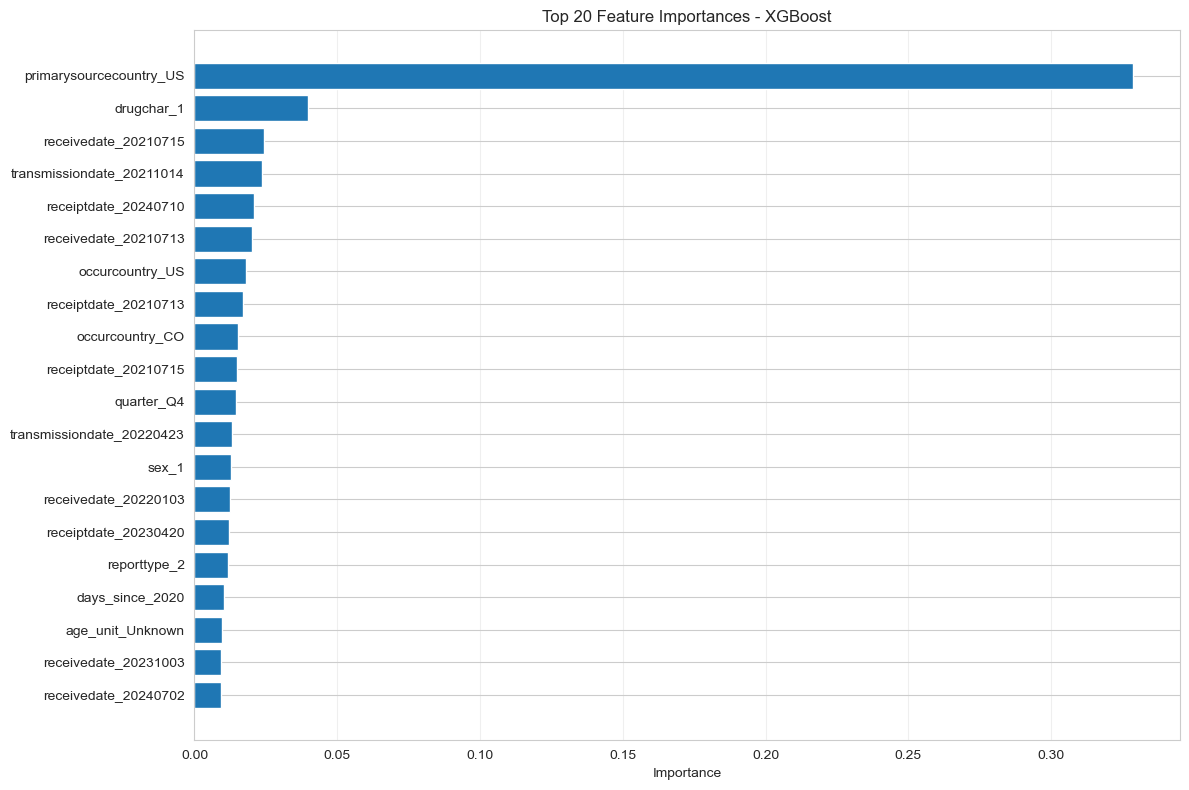


PERMUTATION IMPORTANCE
Using n_repeats=5

Top 20 features by permutation importance:
             feature  importance_mean  importance_std
primarysourcecountry         0.092474        0.000318
          reporttype         0.052915        0.000263
          drugchar_1         0.042076        0.000524
        occurcountry         0.030164        0.000377
     days_since_2020         0.024418        0.000164
       num_reactions         0.018908        0.000116
            age_unit         0.012060        0.000216
                 sex         0.009432        0.000082
           num_drugs         0.004861        0.000185
         receiptdate         0.004401        0.000089
             quarter         0.003201        0.000130
          drugchar_2         0.003160        0.000062
                 age         0.002759        0.000179
                year         0.002479        0.000124
         receivedate         0.002191        0.000090
              weight         0.002006        0.000

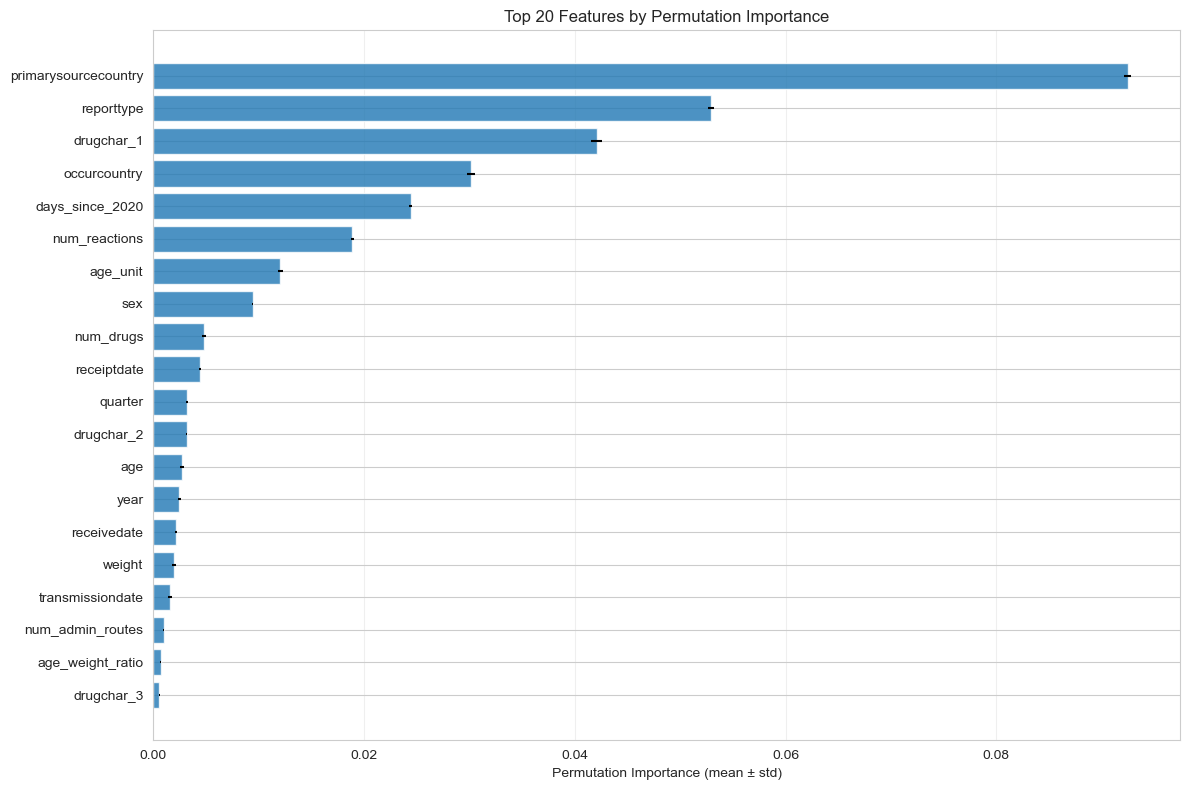


SHAP ANALYSIS: XGBoost
Computing SHAP values for 400 samples...
SHAP values calculated successfully! Shape: (400, 265)


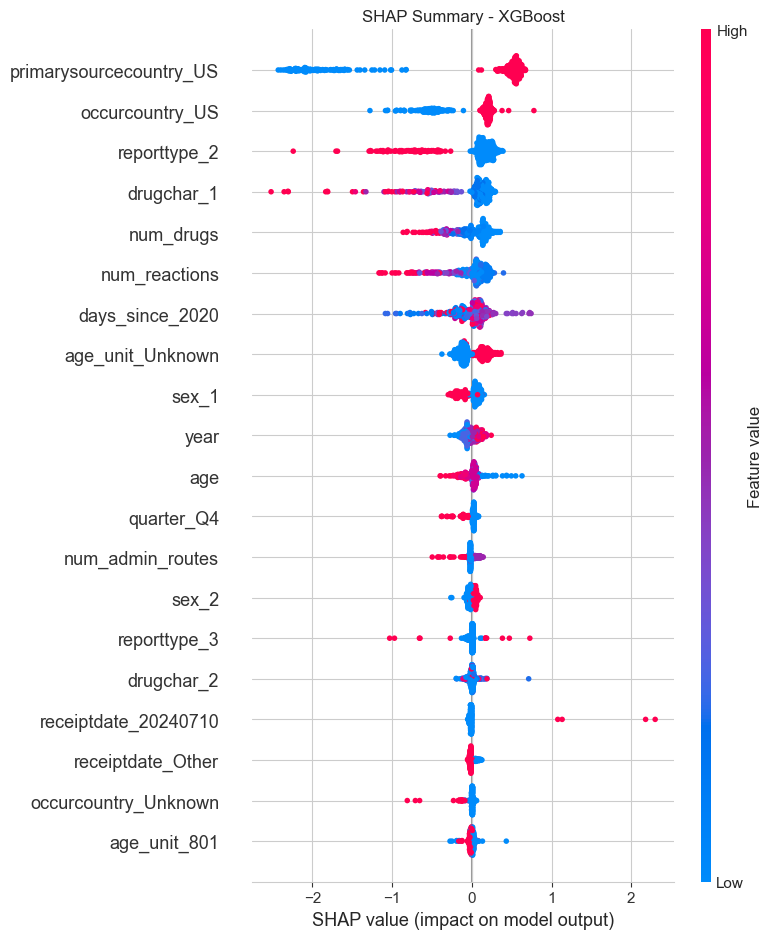

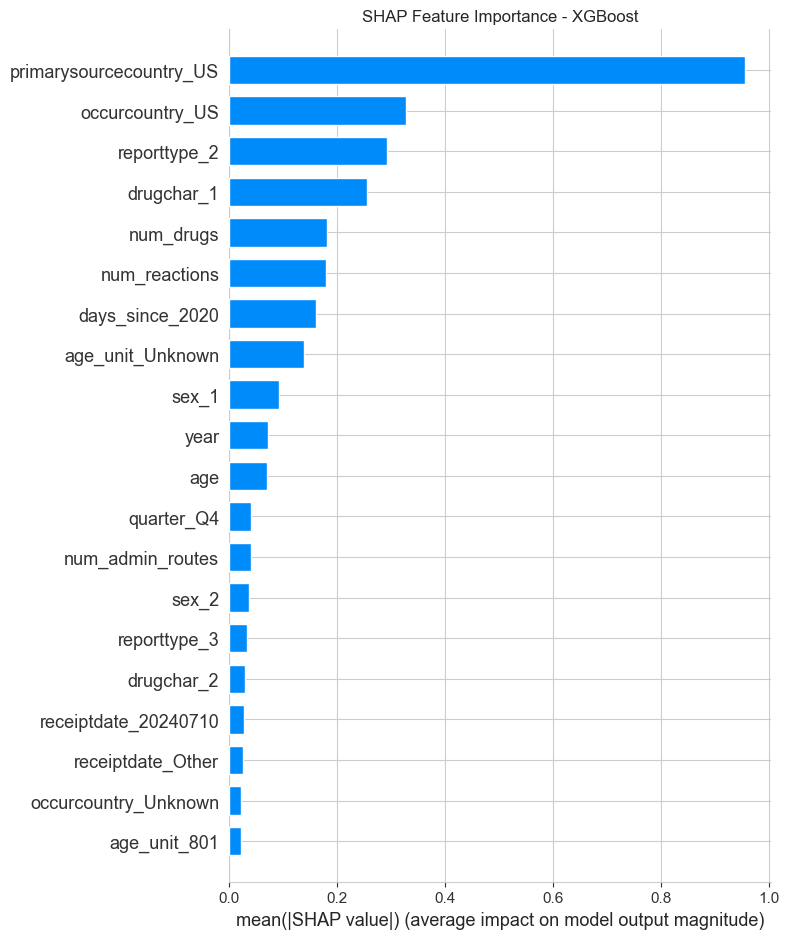

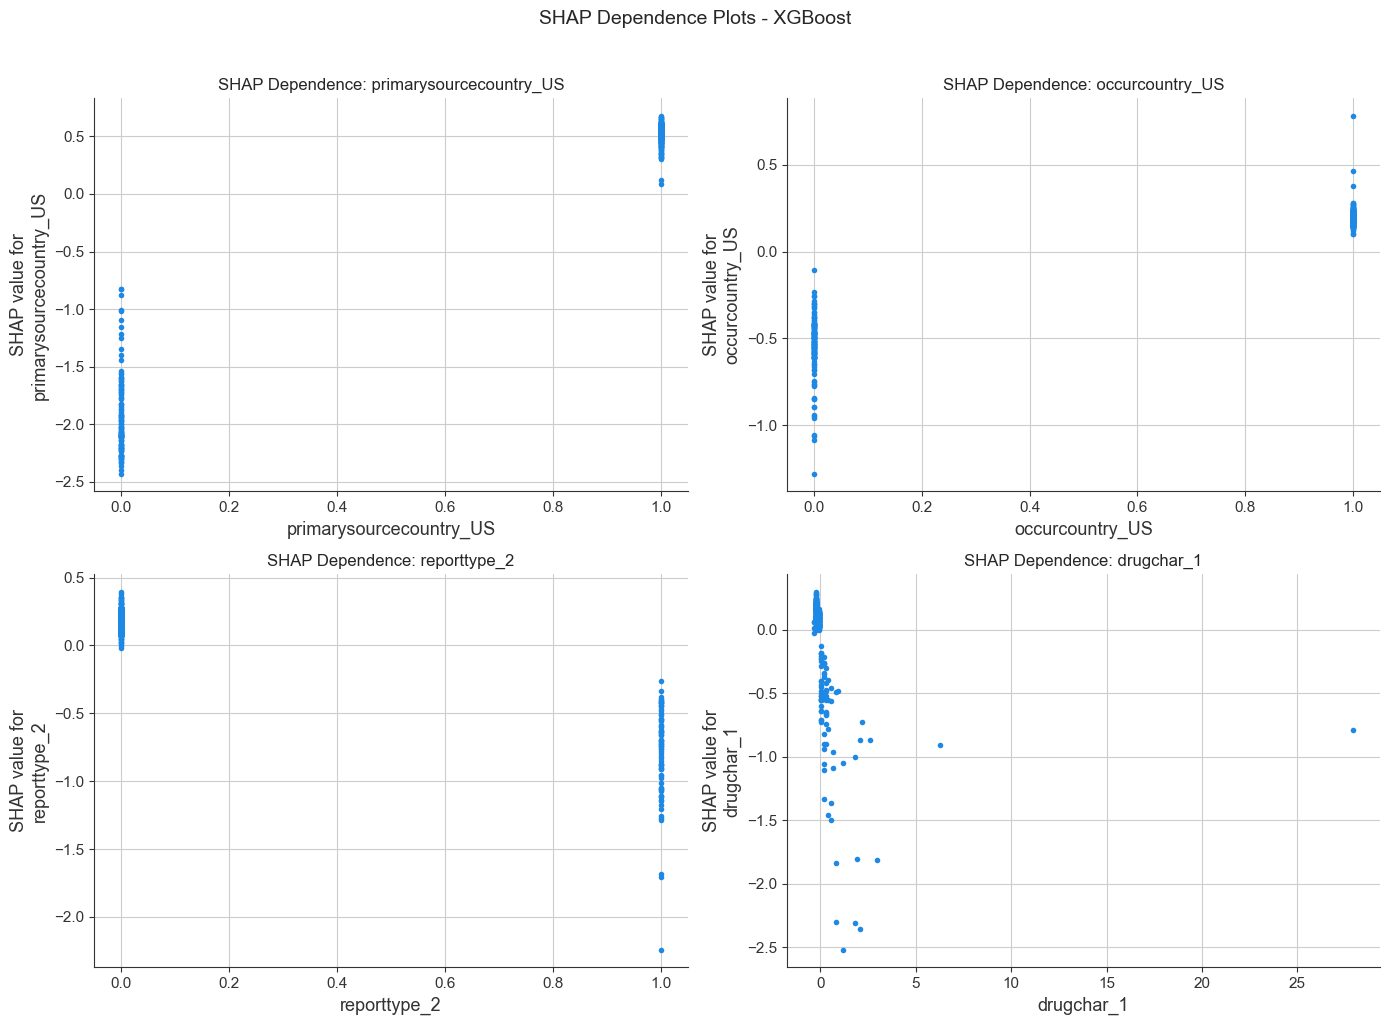


Single-instance explanation for XGBoost (row 0):

Top 10 drivers (by |SHAP|):
                feature     value  shap_value
primarysourcecountry_US  0.000000   -1.974940
        occurcountry_US  0.000000   -0.462857
             drugchar_1  0.053791   -0.192095
           reporttype_2  0.000000    0.120831
        days_since_2020  0.194740    0.102534
                    age -0.038582   -0.097728
              num_drugs -0.110864   -0.097073
                  sex_1  1.000000   -0.086546
          num_reactions  0.310012   -0.073810
           reporttype_3  0.000000   -0.063520

Top positive contributions (pushing towards Serious=1):
                  feature     value  shap_value
             reporttype_2  0.000000    0.120831
          days_since_2020  0.194740    0.102534
               quarter_Q4  0.000000    0.036565
               drugchar_2 -0.297073    0.018751
transmissiondate_20220423  0.000000    0.007805
        receivedate_Other  1.000000    0.006447
transmissiondate_20211

In [35]:
"""
FAERS Adverse Drug Reaction Prediction - Part 5: Interpretability
"""

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.inspection import permutation_importance

# Try to reuse RANDOM_STATE from earlier config, else default
try:
    RANDOM_STATE = config.RANDOM_STATE
except Exception:
    RANDOM_STATE = 42

# ============================================================================
# FEATURE IMPORTANCE
# ============================================================================

def extract_feature_importance(model, X_train_transformed, feature_names, model_name):
    """
    Extract feature importance from trained model.
    Works for tree-based models (feature_importances_) and linear models (coef_).
    """
    print(f"\n{'='*60}")
    print(f"FEATURE IMPORTANCE: {model_name}")
    print(f"{'='*60}")
    
    importance_df = None

    # If it is a Pipeline, grab the classifier step
    if hasattr(model, 'named_steps'):
        if 'clf' in model.named_steps:
            clf = model.named_steps['clf']
        elif 'classifier' in model.named_steps:
            clf = model.named_steps['classifier']
        else:
            clf = list(model.named_steps.values())[-1]
    else:
        clf = model

    # Tree-based models
    if hasattr(clf, 'feature_importances_'):
        importances = clf.feature_importances_
        if feature_names is None or len(feature_names) != len(importances):
            feature_names = [f"feature_{i}" for i in range(len(importances))]
        importance_df = pd.DataFrame({
            'feature': feature_names,
            'importance': importances
        }).sort_values('importance', ascending=False)

        print("\nTop 20 Most Important Features (tree-based):")
        print(importance_df.head(20).to_string(index=False))

    # Linear models
    elif hasattr(clf, 'coef_'):
        coefs = clf.coef_[0]
        if feature_names is None or len(feature_names) != len(coefs):
            feature_names = [f"feature_{i}" for i in range(len(coefs))]
        importance_df = pd.DataFrame({
            'feature': feature_names,
            'coefficient': coefs,
            'abs_coefficient': np.abs(coefs)
        }).sort_values('abs_coefficient', ascending=False)

        print("\nTop 20 Features by Absolute Coefficient (linear):")
        print(importance_df[['feature', 'coefficient', 'abs_coefficient']].head(20).to_string(index=False))

    else:
        print("Model does not expose feature_importances_ or coef_ directly.")

    return importance_df


def plot_feature_importance(importance_df, model_name, top_n=20):
    """
    Plot top feature importances or coefficients.
    """
    if importance_df is None or len(importance_df) == 0:
        print("No feature importance data to plot.")
        return

    top = importance_df.head(top_n)

    plt.figure(figsize=(12, 8))

    if 'importance' in top.columns:
        y = np.arange(len(top))
        plt.barh(y, top['importance'])
        plt.yticks(y, top['feature'])
        plt.xlabel('Importance')
        plt.title(f'Top {top_n} Feature Importances - {model_name}')
        plt.gca().invert_yaxis()

    elif 'coefficient' in top.columns:
        colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in top['coefficient']]
        y = np.arange(len(top))
        plt.barh(y, top['coefficient'], color=colors)
        plt.yticks(y, top['feature'])
        plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
        plt.xlabel('Coefficient')
        plt.title(f'Top {top_n} Coefficients - {model_name}')
        plt.gca().invert_yaxis()

    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ============================================================================
# PERMUTATION IMPORTANCE
# ============================================================================

def calculate_permutation_importance(model, X_test, y_test, feature_names=None, n_repeats=10):
    """
    Model-agnostic permutation importance.
    Uses raw feature names (X_test columns). If lengths mismatch,
    falls back to generic feature_i names.
    """
    print(f"\n{'='*60}")
    print("PERMUTATION IMPORTANCE")
    print(f"{'='*60}")
    print(f"Using n_repeats={n_repeats}")

    result = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=n_repeats,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    n_feats = result.importances_mean.shape[0]

    if feature_names is None or len(feature_names) != n_feats:
        if hasattr(X_test, "columns") and len(X_test.columns) == n_feats:
            feature_names = list(X_test.columns)
        else:
            feature_names = [f"feature_{i}" for i in range(n_feats)]

    perm_df = pd.DataFrame({
        'feature': feature_names,
        'importance_mean': result.importances_mean,
        'importance_std': result.importances_std
    }).sort_values('importance_mean', ascending=False)

    print("\nTop 20 features by permutation importance:")
    print(perm_df.head(20).to_string(index=False))

    return perm_df


def plot_permutation_importance(perm_df, top_n=20):
    """
    Plot permutation importance (mean ± std).
    """
    if perm_df is None or len(perm_df) == 0:
        print("No permutation importance data to plot.")
        return

    top = perm_df.head(top_n)

    plt.figure(figsize=(12, 8))
    y = np.arange(len(top))
    plt.barh(y, top['importance_mean'], xerr=top['importance_std'], alpha=0.8)
    plt.yticks(y, top['feature'])
    plt.xlabel('Permutation Importance (mean ± std)')
    plt.title(f'Top {top_n} Features by Permutation Importance')
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ============================================================================
# SHAP UTIL: NORMALIZE TO 2D ARRAY AND ALIGN WITH X
# ============================================================================

def _normalize_shap_values(shap_values):
    """
    Normalize SHAP outputs to a 2D numpy array [n_samples, n_features].
    Handles:
      - list of per-class arrays
      - shap.Explanation
      - 3D arrays [n_samples, n_classes, n_features]
    """
    # List of arrays (e.g., one per class)
    if isinstance(shap_values, list):
        if len(shap_values) == 1:
            vals = np.array(shap_values[0])
        else:
            vals = np.array(shap_values[1])
    # shap.Explanation object
    elif hasattr(shap_values, "values") and not isinstance(shap_values, np.ndarray):
        vals = np.array(shap_values.values)
    else:
        vals = np.array(shap_values)

    # 3D -> [samples, features] for positive class
    if vals.ndim == 3:
        if vals.shape[1] > 1:
            vals = vals[:, 1, :]
        else:
            vals = vals[:, 0, :]
    # 1D -> single feature
    elif vals.ndim == 1:
        vals = vals.reshape(-1, 1)

    return vals

def _align_shap_and_X(shap_values, X_shap):
    """
    Ensure shap_values.shape[1] == X_shap.shape[1] by trimming
    to the common minimum. This kills the SHAP assertion.
    """
    shap_values = np.asarray(shap_values)
    X_shap = np.asarray(X_shap)

    if shap_values.ndim > 2:
        shap_values = shap_values.reshape(shap_values.shape[0], -1)
    if X_shap.ndim > 2:
        X_shap = X_shap.reshape(X_shap.shape[0], -1)

    n_samples_s, n_features_s = shap_values.shape
    n_samples_x, n_features_x = X_shap.shape

    if n_samples_s != n_samples_x:
        n_min = min(n_samples_s, n_samples_x)
        shap_values = shap_values[:n_min, :]
        X_shap = X_shap[:n_min, :]

    if n_features_s != n_features_x:
        n_feat = min(n_features_s, n_features_x)
        print(f"Aligning SHAP and X: shap_features={n_features_s}, X_features={n_features_x} -> using first {n_feat}")
        shap_values = shap_values[:, :n_feat]
        X_shap = X_shap[:, :n_feat]

    return shap_values, X_shap

# ============================================================================
# SHAP ANALYSIS
# ============================================================================

def calculate_shap_values(model, X_sample, feature_names, model_name):
    """
    Calculate SHAP values for model interpretability.
    Works with a sklearn / imblearn Pipeline with:
      - 'preprocessor' step
      - 'clf' or 'classifier' step
    Returns:
      explainer, shap_values_2d, X_shap (numeric array used for SHAP)
    """
    print(f"\n{'='*60}")
    print(f"SHAP ANALYSIS: {model_name}")
    print(f"{'='*60}")

    # 1. Get classifier and transform features through preprocessor
    if hasattr(model, "named_steps"):
        if 'clf' in model.named_steps:
            clf = model.named_steps['clf']
        elif 'classifier' in model.named_steps:
            clf = model.named_steps['classifier']
        else:
            clf = list(model.named_steps.values())[-1]

        if "preprocessor" in model.named_steps:
            X_trans = model.named_steps["preprocessor"].transform(X_sample)
        else:
            X_trans = X_sample
    else:
        clf = model
        X_trans = X_sample

    # 2. Force numeric matrix for SHAP
    X_trans = np.asarray(X_trans, dtype=np.float64)
    if X_trans.ndim > 2:
        X_trans = X_trans.reshape(X_trans.shape[0], -1)

    # 3. Subsample
    max_samples = min(400, X_trans.shape[0])
    X_shap = X_trans[:max_samples]
    print(f"Computing SHAP values for {max_samples} samples...")

    try:
        # Tree-based models (XGBoost, RF, GBM, etc.)
        if hasattr(clf, "tree_") or hasattr(clf, "get_booster"):
            explainer = shap.TreeExplainer(clf)
            shap_raw = explainer.shap_values(X_shap)

        # Linear models
        elif hasattr(clf, "coef_"):
            explainer = shap.LinearExplainer(clf, X_shap)
            shap_raw = explainer.shap_values(X_shap)

        # General fallback
        else:
            background = shap.sample(X_shap, min(100, X_shap.shape[0]))
            explainer = shap.KernelExplainer(clf.predict_proba, background)
            shap_raw = explainer.shap_values(X_shap)

        # Normalize to [n_samples, n_features]
        shap_values = _normalize_shap_values(shap_raw)

        # Align dimensions with X_shap so SHAP doesn't complain
        shap_values, X_shap = _align_shap_and_X(shap_values, X_shap)

        print(f"SHAP values calculated successfully! Shape: {shap_values.shape}")
        return explainer, shap_values, X_shap

    except Exception as e:
        print(f"Error calculating SHAP values: {e}")
        print("Skipping SHAP and continuing without it.")
        return None, None, None


def plot_shap_summary(shap_values, X_shap, feature_names, model_name):
    """
    SHAP summary (beeswarm + bar).
    Forces shapes to match before calling shap.summary_plot.
    """
    if shap_values is None:
        print("No SHAP values to plot.")
        return

    # Align again defensively
    shap_values, X_shap = _align_shap_and_X(
        np.asarray(shap_values), np.asarray(X_shap, dtype=np.float64)
    )

    if feature_names is None or len(feature_names) != X_shap.shape[1]:
        feature_names = [f"feature_{i}" for i in range(X_shap.shape[1])]

    X_df = pd.DataFrame(X_shap, columns=feature_names)

    # Beeswarm
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_df, show=False, max_display=20)
    plt.title(f'SHAP Summary - {model_name}')
    plt.tight_layout()
    plt.show()

    # Bar
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_df, plot_type='bar', show=False, max_display=20)
    plt.title(f'SHAP Feature Importance - {model_name}')
    plt.tight_layout()
    plt.show()


def plot_shap_dependence(shap_values, X_shap, feature_names, model_name, top_features=4):
    """
    SHAP dependence plots for top features.
    Assumes shap_values is 2D [n_samples, n_features].
    """
    if shap_values is None:
        print("No SHAP values for dependence plots.")
        return

    shap_values, X_shap = _align_shap_and_X(
        np.asarray(shap_values), np.asarray(X_shap, dtype=np.float64)
    )

    if feature_names is None or len(feature_names) != X_shap.shape[1]:
        feature_names = [f"feature_{i}" for i in range(X_shap.shape[1])]

    X_df = pd.DataFrame(X_shap, columns=feature_names)

    # Rank features by mean |SHAP|
    mean_abs = np.abs(shap_values).mean(axis=0)
    top_idx = np.argsort(mean_abs)[-top_features:][::-1]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.ravel()

    for i, idx in enumerate(top_idx[:4]):
        shap.dependence_plot(
            idx,
            shap_values,
            X_df,
            interaction_index=None,
            ax=axes[i],
            show=False
        )
        axes[i].set_title(f"SHAP Dependence: {feature_names[idx]}")

    plt.suptitle(f"SHAP Dependence Plots - {model_name}", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def explain_individual_prediction(explainer, shap_values, X_shap, feature_names,
                                  instance_idx=0, model_name="Model"):
    """
    Text-based explanation for a single prediction (NO force_plot to avoid SHAP UI bugs).
    Prints top positive and negative contributing features for one instance.
    """
    if explainer is None or shap_values is None:
        print("No SHAP explainer/values available.")
        return

    shap_values, X_shap = _align_shap_and_X(
        np.asarray(shap_values), np.asarray(X_shap, dtype=np.float64)
    )

    if feature_names is None or len(feature_names) != X_shap.shape[1]:
        feature_names = [f"feature_{i}" for i in range(X_shap.shape[1])]

    X_df = pd.DataFrame(X_shap, columns=feature_names)

    if instance_idx >= len(X_df):
        instance_idx = 0

    x_row = X_df.iloc[instance_idx]
    shap_row = shap_values[instance_idx]

    contrib_df = pd.DataFrame({
        "feature": feature_names,
        "value": x_row.values,
        "shap_value": shap_row,
        "abs_shap": np.abs(shap_row)
    }).sort_values("abs_shap", ascending=False)

    print(f"\nSingle-instance explanation for {model_name} (row {instance_idx}):")

    print("\nTop 10 drivers (by |SHAP|):")
    print(contrib_df.head(10)[["feature", "value", "shap_value"]].to_string(index=False))

    print("\nTop positive contributions (pushing towards Serious=1):")
    print(contrib_df[contrib_df["shap_value"] > 0].head(10)[["feature", "value", "shap_value"]].to_string(index=False))

    print("\nTop negative contributions (pushing towards Non-Serious=0):")
    print(contrib_df[contrib_df["shap_value"] < 0].head(10)[["feature", "value", "shap_value"]].to_string(index=False))

# ============================================================================
# COMPREHENSIVE INTERPRETABILITY ANALYSIS
# ============================================================================

def run_interpretability_analysis(model, X_train, X_test, y_test,
                                  feature_names, model_name):
    """
    Run feature importance, permutation importance, and SHAP.
    feature_names here should be transformed feature names from the preprocessor
    (for SHAP + built-in importance). Permutation importance uses raw X_test columns.
    """
    print("\n" + "="*80)
    print("INTERPRETABILITY ANALYSIS")
    print("="*80)

    results = {}

    # 1. Built-in feature importance (transformed space)
    importance_df = extract_feature_importance(model, None, feature_names, model_name)
    if importance_df is not None:
        plot_feature_importance(importance_df, model_name)
        results['feature_importance'] = importance_df

    # 2. Permutation importance (raw space)
    if hasattr(X_test, "columns"):
        perm_feature_names = list(X_test.columns)
    else:
        perm_feature_names = None

    perm_df = calculate_permutation_importance(
        model,
        X_test,
        y_test,
        feature_names=perm_feature_names,
        n_repeats=5
    )
    plot_permutation_importance(perm_df)
    results['permutation_importance'] = perm_df

    # 3. SHAP (sample from X_test – raw, then transformed inside function)
    if hasattr(X_test, 'iloc'):
        sample_idx = np.random.choice(len(X_test), min(400, len(X_test)), replace=False)
        X_sample = X_test.iloc[sample_idx]
    else:
        sample_idx = np.random.choice(len(X_test), min(400, len(X_test)), replace=False)
        X_sample = X_test[sample_idx]

    explainer, shap_vals, X_shap = calculate_shap_values(model, X_sample, feature_names, model_name)

    if shap_vals is not None:
        plot_shap_summary(shap_vals, X_shap, feature_names, model_name)
        plot_shap_dependence(shap_vals, X_shap, feature_names, model_name)
        explain_individual_prediction(explainer, shap_vals, X_shap, feature_names,
                                      instance_idx=0, model_name=model_name)

        results['shap_values'] = shap_vals
        results['shap_explainer'] = explainer

    print("\n" + "="*80)
    print("INTERPRETABILITY ANALYSIS COMPLETE")
    print("="*80)

    return results

# ============================================================================
# FEATURE INTERACTION ANALYSIS
# ============================================================================

def analyze_feature_interactions(shap_values, X_shap, feature_names, top_n=10):
    """
    Simple interaction measure: correlation of SHAP values between features.
    Assumes shap_values is 2D [n_samples, n_features].
    """
    if shap_values is None:
        print("No SHAP values for interaction analysis.")
        return

    shap_values, X_shap = _align_shap_and_X(
        np.asarray(shap_values), np.asarray(X_shap, dtype=np.float64)
    )

    if feature_names is None or len(feature_names) != X_shap.shape[1]:
        feature_names = [f"feature_{i}" for i in range(X_shap.shape[1])]

    mean_abs = np.abs(shap_values).mean(axis=0)
    top_idx = np.argsort(mean_abs)[-top_n:][::-1]
    top_features = [feature_names[i] for i in top_idx]

    mat = np.zeros((top_n, top_n))

    for i, idx_i in enumerate(top_idx):
        for j, idx_j in enumerate(top_idx):
            if i == j:
                mat[i, j] = 1.0
            else:
                c = np.corrcoef(shap_values[:, idx_i], shap_values[:, idx_j])[0, 1]
                mat[i, j] = np.abs(c)

    plt.figure(figsize=(10, 8))
    sns.heatmap(mat, annot=True, fmt=".2f",
                xticklabels=top_features,
                yticklabels=top_features,
                cmap='RdYlBu_r')
    plt.title(f"SHAP-based Feature Interaction (Top {top_n})")
    plt.tight_layout()
    plt.show()

    print("\nTop interacting pairs:")
    pairs = []
    for i in range(top_n):
        for j in range(i+1, top_n):
            pairs.append((top_features[i], top_features[j], mat[i, j]))
    pairs = sorted(pairs, key=lambda x: x[2], reverse=True)
    for p in pairs[:10]:
        print(f"{p[0]}  x  {p[1]}  -> interaction strength: {p[2]:.3f}")

# ============================================================================
# SUMMARY PRINTER
# ============================================================================

def print_interpretability_summary(results, model_name):
    """
    Print a short text summary in the notebook.
    """
    print("\n" + "="*80)
    print(f"INTERPRETABILITY SUMMARY: {model_name}")
    print("="*80)

    if 'feature_importance' in results:
        print("\nTop features by built-in importance / coefficients:")
        print(results['feature_importance'].head(10).to_string(index=False))

    if 'permutation_importance' in results:
        print("\nTop features by permutation importance:")
        print(results['permutation_importance'].head(10).to_string(index=False))

    print("\nKey points you can mention in the report:")
    print("- Which features are consistently important across methods.")
    print("- Whether demographic, drug, or reaction features matter more.")
    print("- Any surprising highly important features.")
    print("="*80)

# ============================================================================
# GET TRANSFORMED FEATURE NAMES FROM PREPROCESSOR
# ============================================================================

def get_feature_names_from_preprocessor(preprocessor, numeric_features, categorical_features):
    """
    Build final feature names from ColumnTransformer(preprocessor) with OneHotEncoder.
    """
    feature_names = []

    # numeric features (after scaler, names stay same)
    feature_names.extend(numeric_features)

    # categorical features -> one-hot
    if 'cat' in preprocessor.named_transformers_:
        ohe = preprocessor.named_transformers_['cat'].named_steps['onehot']
        cat_ohe_names = ohe.get_feature_names_out(categorical_features)
        feature_names.extend(cat_ohe_names)

    return feature_names


feature_names = get_feature_names_from_preprocessor(preprocessor, num_feats, cat_feats)
print("Number of final (transformed) features:", len(feature_names))

interp_results = run_interpretability_analysis(
    model=best_model,
    X_train=X_train,
    X_test=X_test,
    y_test=y_test,
    feature_names=feature_names,
    model_name=best_name
)

print_interpretability_summary(interp_results, best_name)
print("Part 5 completed")
